# Metaheurísticas recentes em problemas de engenharia com restrições
### Reprodução do experimento, correção do orçamento computacional e melhorias metodológicas

Este notebook reimplementa o estudo comparativo de cinco metaheurísticas publicadas em 2025 — **BfOA, CCO, LMO, ODO e TIEO** — em problemas clássicos de engenharia com restrições e o estende em três frentes:

| Experimento | O que muda | Por quê |
|---|---|---|
| **A — protocolo original** | $NP=30$ ($16$ no BfOA), 500 iterações, 30 execuções, penalidade exterior com $\lambda=10^{15}$ | reproduzir o desenho do artigo e medir o NFE efetivo de cada método |
| **B — orçamento equalizado** | todos param em $NFE_{\max}=15\,000$ avaliações (incluindo a fase de reconhecimento do BfOA); cronogramas internos indexados pela fração do orçamento | comparação justa de qualidade de solução |
| **C — melhorias metodológicas** | verificação de viabilidade, regras de Deb, sensibilidade a $\lambda$, ótimos de referência recalculados, 8 problemas, Friedman + Iman–Davenport + Nemenyi, Mann–Whitney/Holm, perfis ECDF | robustez das conclusões |
| **D — escalabilidade** | 6 funções deslocadas e rotacionadas (estilo CEC 2017), $D\in\{10, 30, 50\}$, $NFE_{\max}=1000\,D$ | testar se o ranking se mantém em dimensão maior |

> **Fidelidade das implementações.** ODO e LMO seguem as equações do artigo. O CCO segue a lógica do código MATLAB oficial (portado no *mealpy*), consistente com as Eqs. (10)–(24). Para BfOA e TIEO o artigo descreve apenas parte do método; as lacunas foram preenchidas com escolhas explícitas, indicadas como *reconstrução* em cada seção. Os valores absolutos não devem coincidir com os do artigo — o objetivo é um protocolo de comparação correto e reprodutível.

## 0. Configuração

Requisitos: Python ≥ 3.9, `numpy`, `scipy`, `pandas` ≥ 2.1, `matplotlib` ≥ 3.7, `joblib` e `ipython`/Jupyter.

Os resultados de cada experimento ficam em `cache_metaheuristicas/`, ao lado do notebook; com `RECOMPUTE = False`, uma nova execução reaproveita o cache. A execução completa (≈6 000 execuções) leva da ordem de 40 min em 2 núcleos e cai proporcionalmente com mais núcleos (`N_JOBS = -1` usa todos). Para um teste rápido, reduza `RUNS`, `RUNS_LAM` e `RUNS_D` (por exemplo, para 3) e use outra pasta em `CACHE`.

In [1]:
import os
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(v, "1")

import itertools, math, pickle, platform, time, warnings, zlib
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from scipy import stats
from scipy.optimize import minimize
from joblib import Parallel, delayed
from IPython.display import display, Markdown

RUNS, MAX_ITER, NFE_MAX, LAMBDA = 30, 500, 15_000, 1e15
RUNS_LAM, RUNS_D, NFE_PER_D, SCAL_DIMS = 15, 10, 1000, (10, 30, 50)
FEAS_TOL, SEED, N_JOBS, RECOMPUTE = 1e-8, 2025, -1, False
CACHE = Path("cache_metaheuristicas")
CACHE.mkdir(exist_ok=True)
FIGS = Path("figs")
FIGS.mkdir(exist_ok=True)

ALG_NAMES = ["BfOA", "CCO", "LMO", "ODO", "TIEO"]
COLORS = dict(zip(ALG_NAMES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
MARKERS = dict(zip(ALG_NAMES, "osD^v"))
INK, INK2, MUTED, SURFACE = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 60)

# Base seaborn theme — estilos personalizados abaixo sobrescrevem conforme necessário
sns.set_theme(style="white", font_scale=1.0)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8, "axes.grid": True, "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 10.5, "font.size": 9.5,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "lines.linewidth": 1.6, "figure.dpi": 110, "figure.constrained_layout.use": True,
    # Fonte matemática Computer Modern (padrão LaTeX) via mathtext do matplotlib
    "mathtext.fontset": "cm",
})
print(f"Python {platform.python_version()} | numpy {np.__version__} | scipy {scipy.__version__} | "
      f"pandas {pd.__version__} | matplotlib {mpl.__version__} | seaborn {sns.__version__} | núcleos: {os.cpu_count()}")


Python 3.14.7 | numpy 2.5.4 | scipy 1.18.1 | pandas 3.0.6 | matplotlib 3.11.2 | seaborn 0.13.2 | núcleos: 12


## 1. Problemas de otimização

Todas as restrições estão na forma normalizada $g_i(\mathbf x)\le 0$ (razões adimensionais), o que torna as violações comparáveis entre si — condição para que a penalidade e as regras de Deb ponderem as restrições de modo equilibrado. Os cinco primeiros problemas são os do artigo; os três últimos ampliam o conjunto no Exp. C.

**Welded Beam** — $\mathbf x=(h,l,t,b)$, $\;h,b\in[0{,}1;\,2]$, $\;l,t\in[0{,}1;\,10]$

$$\min f = 1{,}10471\,h^2 l + 0{,}04811\,t\,b\,(14+l)$$

$$g_1=\frac{\tau}{\tau_{\max}}-1,\quad g_2=\frac{\sigma}{\sigma_{\max}}-1,\quad g_3=\frac hb-1,\quad g_4=\frac{0{,}10471\,h^2+0{,}04811\,tb\,(14+l)}{5}-1,\quad g_5=1-\frac{h}{0{,}125},\quad g_6=\frac{\delta}{\delta_{\max}}-1,\quad g_7=1-\frac{P_c}{P}$$

$$\tau=\sqrt{\tau'^2+\tau'\tau''\,\frac lR+\tau''^2},\quad \tau'=\frac{P}{\sqrt2\,hl},\quad \tau''=\frac{P\,(L+l/2)\,R}{J},\quad R=\sqrt{\frac{l^2}{4}+\Big(\frac{h+t}{2}\Big)^2},\quad J=2\sqrt2\,hl\Big[\frac{l^2}{12}+\Big(\frac{h+t}{2}\Big)^2\Big]$$

$$\sigma=\frac{6PL}{bt^2},\qquad \delta=\frac{4PL^3}{Et^3b},\qquad P_c=\frac{4{,}013\,E\sqrt{t^2b^6/36}}{L^2}\Big(1-\frac{t}{2L}\sqrt{\frac{E}{4G}}\Big)$$

com $P=6000$ lb, $L=14$ in, $E=30\times10^6$ psi, $G=12\times10^6$ psi, $\tau_{\max}=13\,600$ psi, $\sigma_{\max}=30\,000$ psi e $\delta_{\max}=0{,}25$ in.

**Cantilever Beam** — $x_i\in[0{,}01;\,100]$

$$\min f=0{,}0624\,(x_1+x_2+x_3+x_4+x_5),\qquad g_1=\frac{61}{x_1^3}+\frac{37}{x_2^3}+\frac{19}{x_3^3}+\frac{7}{x_4^3}+\frac{1}{x_5^3}-1$$

**Three-Bar Truss** — $A_1,A_2\in[0;\,1]$, $\;\ell=100$ cm, $\;P=\sigma=2$ kN/cm²

$$\min f=\ell\,(2\sqrt2A_1+A_2),\quad g_1=\frac{\sqrt2A_1+A_2}{\sqrt2A_1^2+2A_1A_2}\,\frac P\sigma-1,\quad g_2=\frac{A_2}{\sqrt2A_1^2+2A_1A_2}\,\frac P\sigma-1,\quad g_3=\frac{1}{A_1+\sqrt2A_2}\,\frac P\sigma-1$$

**I-Beam Deflection** — $b\in[10;\,50]$, $\;h\in[10;\,80]$, $\;t_w,t_f\in[0{,}9;\,5]$

$$\min f=\frac{5000}{I},\qquad I=\frac{t_w(h-2t_f)^3}{12}+\frac{b\,t_f^3}{6}+2\,b\,t_f\Big(\frac{h-t_f}{2}\Big)^2$$

$$g_1=\frac{2bt_f+t_w(h-2t_f)}{300}-1,\qquad g_2=\frac16\left[\frac{18\cdot10^4\,h}{t_w(h-2t_f)^3+2b\,\boldsymbol{t_f}\big(4t_f^2+3h(h-2t_f)\big)}+\frac{15\cdot10^3\,b}{(h-2t_f)\,t_w^3+2\,\boldsymbol{t_f}\,b^3}\right]-1$$

Os termos em negrito vêm dos momentos de inércia da seção ($I_y$ e $I_z$). A forma difundida na literatura traz $t_w$ no lugar desses dois $t_f$; é ela que reproduz o resultado do artigo, $f=0{,}014927$ em $(50;\,80;\,1{,}5524;\,1{,}8144)$, enquanto a forma correta recupera o valor de referência citado, $f^*=0{,}0130741$. A variante do artigo é usada nos Exps. A e B (**I-Beam (artigo)**) e a corrigida no Exp. C (**I-Beam**).

**Tubular Column** — $d\in[2;\,14]$, $\;t\in[0{,}2;\,0{,}8]$, $\;P=2500$ kgf, $\;\sigma_y=500$ kgf/cm², $\;E=0{,}85\times10^6$ kgf/cm², $\;L=250$ cm

$$\min f=9{,}8\,dt+2d,\quad g_1=\frac{P}{\pi dt\sigma_y}-1,\quad g_2=\frac{8PL^2}{\pi^3Edt\,(d^2+t^2)}-1,\quad g_3=\frac2d-1,\quad g_4=\frac{d}{14}-1,\quad g_5=\frac{0{,}2}{t}-1,\quad g_6=\frac{t}{0{,}8}-1$$

**Pressure Vessel** (Exp. C, versão contínua) — $T_s,T_h\in[0;\,99]$, $\;R,L\in[10;\,200]$

$$\min f=0{,}6224\,T_sRL+1{,}7781\,T_hR^2+3{,}1661\,T_s^2L+19{,}84\,T_s^2R$$

$$g_1=1-\frac{T_s}{0{,}0193\,R},\quad g_2=1-\frac{T_h}{0{,}00954\,R},\quad g_3=1-\frac{\pi R^2L+\tfrac43\pi R^3}{1\,296\,000},\quad g_4=\frac{L}{240}-1$$

**Tension/Compression Spring** (Exp. C) — $d\in[0{,}05;\,2]$, $\;D\in[0{,}25;\,1{,}3]$, $\;N\in[2;\,15]$

$$\min f=(N+2)\,D\,d^2,\quad g_1=1-\frac{D^3N}{71\,785\,d^4},\quad g_2=\frac{4D^2-dD}{12\,566\,(Dd^3-d^4)}+\frac{1}{5108\,d^2}-1,\quad g_3=1-\frac{140{,}45\,d}{D^2N},\quad g_4=\frac{D+d}{1{,}5}-1$$

**Speed Reducer** (Exp. C) — $x_1\in[2{,}6;\,3{,}6]$, $x_2\in[0{,}7;\,0{,}8]$, $x_3\in[17;\,28]$, $x_4,x_5\in[7{,}3;\,8{,}3]$, $x_6\in[2{,}9;\,3{,}9]$, $x_7\in[5;\,5{,}5]$

$$\min f=0{,}7854\,x_1x_2^2\,(3{,}3333x_3^2+14{,}9334x_3-43{,}0934)-1{,}508\,x_1(x_6^2+x_7^2)+7{,}4777\,(x_6^3+x_7^3)+0{,}7854\,(x_4x_6^2+x_5x_7^2)$$

$$g_1=\frac{27}{x_1x_2^2x_3}-1,\quad g_2=\frac{397{,}5}{x_1x_2^2x_3^2}-1,\quad g_3=\frac{1{,}93\,x_4^3}{x_2x_3x_6^4}-1,\quad g_4=\frac{1{,}93\,x_5^3}{x_2x_3x_7^4}-1,\quad g_5=\frac{\sqrt{(745x_4/x_2x_3)^2+16{,}9\cdot10^6}}{110\,x_6^3}-1$$

$$g_6=\frac{\sqrt{(745x_5/x_2x_3)^2+157{,}5\cdot10^6}}{85\,x_7^3}-1,\quad g_7=\frac{x_2x_3}{40}-1,\quad g_8=\frac{5x_2}{x_1}-1,\quad g_9=\frac{x_1}{12x_2}-1,\quad g_{10}=\frac{1{,}5x_6+1{,}9}{x_4}-1,\quad g_{11}=\frac{1{,}1x_7+1{,}9}{x_5}-1$$

As funções aceitam tanto colunas de uma matriz (avaliação da população inteira) quanto escalares Python (avaliação individual rápida, usada pelo CCO, que atualiza um indivíduo por vez).

In [2]:
SQ2, PI = 2 ** 0.5, math.pi


@dataclass
class Problem:
    name: str
    lb: np.ndarray
    ub: np.ndarray
    fun: callable
    f_lit: float
    labels: tuple
    scalar: bool = True
    matrix: bool = False
    f_ref: float = np.nan
    x_ref: np.ndarray = None

    @property
    def dim(self):
        return self.lb.size

    def evaluate(self, X):
        X = np.atleast_2d(X)
        n = len(X)
        with np.errstate(all="ignore"):
            f, g = self.fun(X) if self.matrix else self.fun(*X.T)
            f = np.broadcast_to(np.asarray(f, float), (n,)).copy()
            g = np.column_stack([np.broadcast_to(np.asarray(v, float), (n,)) for v in g]) if len(g) else np.zeros((n, 0))
        return np.where(np.isfinite(f), f, 1e300), np.where(np.isnan(g), 1e300, np.clip(g, -1e300, 1e300))

    def evaluate1(self, x):
        if self.scalar:
            try:
                f, g = self.fun(*x.tolist())
                if type(f) is float and all(type(v) is float for v in g):
                    return (f if math.isfinite(f) else 1e300), tuple(1e300 if v != v else max(-1e300, min(v, 1e300)) for v in g)
            except (ZeroDivisionError, OverflowError, ValueError):
                pass
        f, g = self.evaluate(x[None])
        return float(f[0]), tuple(g[0].tolist())


def welded_beam(h, l, t, b):
    P, L, E, G = 6000.0, 14.0, 30e6, 12e6
    f = 1.10471 * h**2 * l + 0.04811 * t * b * (14.0 + l)
    tau1 = P / (SQ2 * h * l)
    R = (l**2 / 4 + ((h + t) / 2) ** 2) ** 0.5
    J = 2 * SQ2 * h * l * (l**2 / 12 + ((h + t) / 2) ** 2)
    tau2 = P * (L + l / 2) * R / J
    tau = (tau1**2 + tau1 * tau2 * l / R + tau2**2) ** 0.5
    sigma = 6 * P * L / (b * t**2)
    delta = 4 * P * L**3 / (E * t**3 * b)
    Pc = 4.013 * E * (t**2 * b**6 / 36) ** 0.5 / L**2 * (1 - t / (2 * L) * (E / (4 * G)) ** 0.5)
    return f, (tau / 13600 - 1, sigma / 30000 - 1, h / b - 1,
               (0.10471 * h**2 + 0.04811 * t * b * (14.0 + l)) / 5 - 1,
               1 - h / 0.125, delta / 0.25 - 1, 1 - Pc / P)


def cantilever(x1, x2, x3, x4, x5):
    return 0.0624 * (x1 + x2 + x3 + x4 + x5), (61 / x1**3 + 37 / x2**3 + 19 / x3**3 + 7 / x4**3 + 1 / x5**3 - 1,)


def three_bar(A1, A2):
    l, P, s = 100.0, 2.0, 2.0
    den = SQ2 * A1**2 + 2 * A1 * A2
    return (2 * SQ2 * A1 + A2) * l, ((SQ2 * A1 + A2) / den * P / s - 1, A2 / den * P / s - 1,
                                     1 / (SQ2 * A2 + A1) * P / s - 1)


def i_beam(b, h, tw, tf, c=None):
    c = tf if c is None else c
    I = tw * (h - 2 * tf) ** 3 / 12 + b * tf**3 / 6 + 2 * b * tf * ((h - tf) / 2) ** 2
    s1 = 18e4 * h / (tw * (h - 2 * tf) ** 3 + 2 * b * c * (4 * tf**2 + 3 * h * (h - 2 * tf)))
    s2 = 15e3 * b / ((h - 2 * tf) * tw**3 + 2 * c * b**3)
    return 5000 / I, ((2 * b * tf + tw * (h - 2 * tf)) / 300 - 1, (s1 + s2) / 6 - 1)


def i_beam_article(b, h, tw, tf):
    return i_beam(b, h, tw, tf, c=tw)


def tubular_column(d, t):
    P, sy, E, L = 2500.0, 500.0, 0.85e6, 250.0
    return 9.8 * d * t + 2 * d, (P / (PI * d * t * sy) - 1, 8 * P * L**2 / (PI**3 * E * d * t * (d**2 + t**2)) - 1,
                                 2 / d - 1, d / 14 - 1, 0.2 / t - 1, t / 0.8 - 1)


def pressure_vessel(Ts, Th, R, L):
    f = 0.6224 * Ts * R * L + 1.7781 * Th * R**2 + 3.1661 * Ts**2 * L + 19.84 * Ts**2 * R
    return f, (1 - Ts / (0.0193 * R), 1 - Th / (0.00954 * R),
               1 - (PI * R**2 * L + 4 / 3 * PI * R**3) / 1296000, L / 240 - 1)


def spring(d, D, N):
    return (N + 2) * D * d**2, (1 - D**3 * N / (71785 * d**4),
                                (4 * D**2 - d * D) / (12566 * (D * d**3 - d**4)) + 1 / (5108 * d**2) - 1,
                                1 - 140.45 * d / (D**2 * N), (D + d) / 1.5 - 1)


def speed_reducer(x1, x2, x3, x4, x5, x6, x7):
    f = (0.7854 * x1 * x2**2 * (3.3333 * x3**2 + 14.9334 * x3 - 43.0934) - 1.508 * x1 * (x6**2 + x7**2)
         + 7.4777 * (x6**3 + x7**3) + 0.7854 * (x4 * x6**2 + x5 * x7**2))
    return f, (27 / (x1 * x2**2 * x3) - 1, 397.5 / (x1 * x2**2 * x3**2) - 1,
               1.93 * x4**3 / (x2 * x3 * x6**4) - 1, 1.93 * x5**3 / (x2 * x3 * x7**4) - 1,
               ((745 * x4 / (x2 * x3)) ** 2 + 16.9e6) ** 0.5 / (110 * x6**3) - 1,
               ((745 * x5 / (x2 * x3)) ** 2 + 157.5e6) ** 0.5 / (85 * x7**3) - 1,
               x2 * x3 / 40 - 1, 5 * x2 / x1 - 1, x1 / (12 * x2) - 1,
               (1.5 * x6 + 1.9) / x4 - 1, (1.1 * x7 + 1.9) / x5 - 1)


def problem(name, lb, ub, fun, f_lit, labels):
    return Problem(name, np.array(lb, float), np.array(ub, float), fun, f_lit, tuple(labels.split()))


PROBLEMS = {p.name: p for p in [
    problem("Welded Beam", [0.1] * 4, [2, 10, 10, 2], welded_beam, 1.7249, "h l t b"),
    problem("Cantilever Beam", [0.01] * 5, [100] * 5, cantilever, 1.3400, "x1 x2 x3 x4 x5"),
    problem("Three-Bar Truss", [0, 0], [1, 1], three_bar, 263.8958, "A1 A2"),
    problem("I-Beam (artigo)", [10, 10, 0.9, 0.9], [50, 80, 5, 5], i_beam_article, 0.0131, "b h tw tf"),
    problem("I-Beam", [10, 10, 0.9, 0.9], [50, 80, 5, 5], i_beam, 0.0130741, "b h tw tf"),
    problem("Tubular Column", [2, 0.2], [14, 0.8], tubular_column, 26.4995, "d t"),
    problem("Pressure Vessel", [0, 0, 10, 10], [99, 99, 200, 200], pressure_vessel, 5885.3328, "Ts Th R L"),
    problem("Spring", [0.05, 0.25, 2], [2, 1.3, 15], spring, 0.0126652, "d D N"),
    problem("Speed Reducer", [2.6, 0.7, 17, 7.3, 7.3, 2.9, 5], [3.6, 0.8, 28, 8.3, 8.3, 3.9, 5.5], speed_reducer,
            2994.4711, "x1 x2 x3 x4 x5 x6 x7"),
]}
SCALABLE_PROBLEMS = {}
PROBS_ART = ["Welded Beam", "Cantilever Beam", "Three-Bar Truss", "I-Beam (artigo)", "Tubular Column"]
PROBS_EXT = ["Welded Beam", "Cantilever Beam", "Three-Bar Truss", "I-Beam", "Tubular Column",
             "Pressure Vessel", "Spring", "Speed Reducer"]

### 1.1 Valores de referência

O artigo compara os resultados com valores da literatura, sem verificar se correspondem exatamente à formulação implementada (o caso do I-Beam mostra que não). Aqui $f^*$ é recalculado para cada formulação por SLSQP com 100 partidas aleatórias, impondo $g_i(\mathbf x)\le-10^{-13}$ para garantir viabilidade estrita do ponto de referência. A tabela também traz a fração de pontos viáveis em $2\times10^4$ amostras uniformes — um indicador da dificuldade de encontrar a região viável — e o limitante $f_{\sup}$ usado pelas regras de Deb (Seção 2).

In [3]:
def reference(prob, starts=100, seed=0, margin=1e-13):
    rng = np.random.default_rng(seed)
    lb, sc = prob.lb, prob.ub - prob.lb
    fs = max(abs(prob.evaluate(lb + sc / 2)[0][0]), 1e-12)
    obj = lambda z: prob.evaluate(lb + z * sc)[0][0] / fs
    con = {"type": "ineq", "fun": lambda z: -prob.evaluate(lb + z * sc)[1][0] - margin}
    best = (np.inf, None)
    for _ in range(starts):
        r = minimize(obj, rng.random(prob.dim), method="SLSQP", bounds=[(0, 1)] * prob.dim,
                     constraints=[con], options={"maxiter": 2000, "ftol": 1e-16})
        x = lb + np.clip(r.x, 0, 1) * sc
        f, g = prob.evaluate(x)
        if g.max() <= 0 and f[0] < best[0]:
            best = (f[0], x)
    return best


def sampling(prob, n=20_000, seed=0):
    rng = np.random.default_rng(seed)
    Z = np.vstack((rng.random((n, prob.dim)), list(itertools.product([0, 1], repeat=prob.dim))))
    f, g = prob.evaluate(prob.lb + Z * (prob.ub - prob.lb))
    return 10 * np.abs(f[f < 1e300]).max() + 1, np.mean(g[:n].max(1) <= 0)


path = CACHE / "referencias.pkl"
if path.exists() and not RECOMPUTE:
    REF = pickle.load(open(path, "rb"))
else:
    REF = {name: (*reference(p), *sampling(p)) for name, p in PROBLEMS.items()}
    pickle.dump(REF, open(path, "wb"))

for name, (f, x, fsup, feas) in REF.items():
    PROBLEMS[name].f_ref, PROBLEMS[name].x_ref = f, x
F_SUP = {name: REF[name][2] for name in PROBLEMS}

rows = []
for name, p in PROBLEMS.items():
    g = p.evaluate(p.x_ref)[1][0]
    rows.append({"Problema": name, "D": p.dim, "m": g.size, "f* literatura": f"{p.f_lit:g}",
                 "f* (SLSQP)": f"{p.f_ref:.10g}", "x*": np.round(p.x_ref, 5).tolist(),
                 "ativas": " ".join(f"g{i + 1}" for i in np.flatnonzero(g > -1e-6)),
                 "viáveis (amostragem)": f"{100 * REF[name][3]:.2f} %", "f_sup": f"{REF[name][2]:.3g}"})
display(pd.DataFrame(rows).set_index("Problema"))

,D,m,f* literatura,f* (SLSQP),x*,ativas,viáveis (amostragem),f_sup
Problema,,,,,,,,
Welded Beam,4,7,1.7249,1.724852309,"[0.20573, 3.47049, 9.03662, 0.20573]",g1 g2 g3 g7,2.68 %,674
Cantilever Beam,5,1,1.34,1.339956361,"[6.01602, 5.30917, 4.49433, 3.50147, 2.15266]",g1,87.83 %,313
Three-Bar Truss,2,3,263.896,263.8958434,"[0.78868, 0.40825]",g1,21.81 %,3.83e+03
I-Beam (artigo),4,2,0.0131,0.01492713046,"[50.0, 80.0, 1.55242, 1.8144]",g1 g2,1.53 %,121
I-Beam,4,2,0.0130741,0.01307411891,"[50.0, 80.0, 0.9, 2.32179]",g1,0.15 %,121
Tubular Column,2,6,26.4995,26.49949689,"[5.45116, 0.29197]",g1 g2,76.73 %,1.38e+03
Pressure Vessel,4,4,5885.33,5885.332774,"[0.77817, 0.38465, 40.31962, 200.0]",g1 g2 g3,75.83 %,5.46e+08
Spring,3,4,0.0126652,0.01266523279,"[0.05169, 0.35672, 11.28898]",g1 g2,0.73 %,885
Speed Reducer,7,11,2994.47,2994.471066,"[3.5, 0.7, 17.0, 7.3, 7.71532, 3.35021, 5.28665]",g5 g6 g8 g11,0.10 %,7.14e+04


## 2. Tratamento de restrições e controle do orçamento

**Penalidade exterior estática** (artigo):

$$F(\mathbf x)=f(\mathbf x)+\lambda\sum_{i=1}^{m}\max\{0,\,g_i(\mathbf x)\}^2,\qquad \lambda=10^{15}.$$

**Regras de Deb** (melhoria): ao comparar duas soluções, (i) a viável vence a inviável; (ii) entre viáveis vence a de menor $f$; (iii) entre inviáveis vence a de menor violação total $CV(\mathbf x)=\sum_i\max\{0,g_i(\mathbf x)\}$. As três regras são preservadas exatamente pela escalarização lexicográfica

$$F_{\text{Deb}}(\mathbf x)=\begin{cases}f(\mathbf x), & CV(\mathbf x)=0\\ f_{\sup}+CV(\mathbf x), & CV(\mathbf x)>0\end{cases}\qquad f_{\sup}>\max_{\mathbf x\in\Omega}f(\mathbf x),$$

o que permite trocar o tratamento de restrições sem alterar nenhum algoritmo.

**Orçamento.** A classe `Task` conta cada avaliação e encerra a busca em $T$ iterações (Exp. A) ou ao atingir $NFE_{\max}$ (demais experimentos); no segundo caso, avaliações além do orçamento não são realizadas. Os parâmetros que dependem do tempo usam o progresso

$$p=\begin{cases}t/T, & \text{protocolo por iterações}\\ NFE/NFE_{\max}, & \text{protocolo por orçamento}\end{cases}$$

de modo que cada algoritmo percorre todo o seu cronograma exploração → explotação dentro do mesmo número de avaliações. A melhor solução é registrada a cada avaliação (desempenho *anytime*), o que permite curvas de convergência em função do NFE. Limites são tratados por projeção, $x_j\leftarrow\min\{\max\{x_j,lb_j\},ub_j\}$, em todos os algoritmos. Uma solução final é considerada **viável** se $\max_i g_i(\mathbf x)\le10^{-8}$.

In [4]:
class Task:
    def __init__(self, prob, max_nfe=None, max_iter=None, handler="penalty", lam=LAMBDA, f_sup=None, checkpoints=()):
        self.prob, self.lb, self.ub, self.dim = prob, prob.lb, prob.ub, prob.dim
        self.max_nfe, self.max_iter = max_nfe, max_iter
        self.handler, self.lam, self.f_sup = handler, lam, f_sup
        self.nfe = self.it = self.k = 0
        self.best, self.xbest, self.fbest, self.gbest = np.inf, None, np.nan, np.zeros(0)
        self.cp = np.asarray(checkpoints, dtype=int)
        self.curve = np.full(self.cp.size, np.nan)
        self.curve_it = []

    def fitness(self, f, g):
        v = np.maximum(g, 0.0)
        if self.handler == "penalty":
            return np.minimum(f + self.lam * (v**2).sum(1), 1e300)
        cv = v.sum(1)
        return np.where(cv > 0, self.f_sup + cv, f)

    def init(self, n, rng):
        return self.lb + rng.random((n, self.dim)) * (self.ub - self.lb)

    def __call__(self, X):
        X = np.atleast_2d(X)
        n = len(X)
        m = n if self.max_nfe is None else max(0, min(n, self.max_nfe - self.nfe))
        F = np.full(n, np.inf)
        if m == 0:
            return F
        f, g = self.prob.evaluate(X[:m])
        with np.errstate(all="ignore"):
            fit = self.fitness(f, g)
        fit[~np.isfinite(X[:m]).all(1)] = np.inf
        F[:m] = fit
        if self.k < self.cp.size and self.cp[self.k] <= self.nfe + m:
            run = np.minimum.accumulate(np.r_[self.best, fit])[1:]
            while self.k < self.cp.size and self.cp[self.k] <= self.nfe + m:
                self.curve[self.k] = run[self.cp[self.k] - self.nfe - 1]
                self.k += 1
        i = int(np.argmin(fit))
        if fit[i] < self.best:
            self.best, self.xbest, self.fbest, self.gbest = fit[i], X[i].copy(), f[i], g[i].copy()
        self.nfe += m
        return F

    def one(self, x):
        if self.max_nfe is not None and self.nfe >= self.max_nfe:
            return np.inf
        f, g = self.prob.evaluate1(x)
        if self.handler == "penalty":
            fit = min(f + self.lam * sum(v * v for v in g if v > 0), 1e300)
        else:
            cv = sum(v for v in g if v > 0)
            fit = self.f_sup + cv if cv > 0 else f
        if not np.isfinite(x).all():
            fit = np.inf
        self.nfe += 1
        if self.k < self.cp.size and self.cp[self.k] == self.nfe:
            self.curve[self.k] = min(self.best, fit)
            self.k += 1
        if fit < self.best:
            self.best, self.xbest, self.fbest, self.gbest = fit, x.copy(), f, np.array(g)
        return fit

    @property
    def progress(self):
        if self.max_nfe is not None:
            return min(1.0, self.nfe / self.max_nfe)
        return min(1.0, self.it / self.max_iter)

    def next(self):
        self.curve_it.append(self.best)
        self.it += 1
        if self.max_nfe is not None and self.nfe >= self.max_nfe:
            return False
        return self.max_iter is None or self.it <= self.max_iter

## 3. Metaheurísticas

Todas recebem uma `Task` e um gerador aleatório, inicializam a população uniformemente no domínio, $\mathbf x_i=\mathbf{lb}+\mathbf r\odot(\mathbf{ub}-\mathbf{lb})$, e repetem iterações enquanto `task.next()` permitir. Notação: $\mathbf r, r$ — uniformes em $[0,1]$; $\boldsymbol\xi$ — normal padrão; $p$ — progresso (Seção 2).

Para comparar outra implementação (por exemplo, o código original do BfOA ou do TIEO), basta escrever uma função `alg(task, rng)` que avalie soluções com `task(X)` ou `task.one(x)` e itere enquanto `task.next()` for verdadeiro, e registrá-la em `ALGS`: orçamento, tratamento de restrições e registro da convergência ficam todos na `Task`.

### 3.1 BfOA — Battlefield Optimization Algorithm *(reconstrução)*

O artigo especifica a fase de reconhecimento (Eq. 7), o movimento do comandante (Eq. 8), a regra de aceitação (Eq. 9) e as constantes da Tabela 2; as demais regras foram completadas como abaixo. Os movimentos ocorrem em coordenadas normalizadas $\mathbf z=(\mathbf x-\mathbf{lb})/(\mathbf{ub}-\mathbf{lb})\in[0,1]^D$, para que as constantes $C$ tenham o mesmo significado em todos os problemas.

**Fase 1 — reconhecimento aéreo.** $N_{air}=20$ aeronaves partem de pontos aleatórios e fazem $N_{eval}=100$ avaliações cada, em movimento browniano geométrico:

$$\mathbf{apl}_{s+1}=\mathbf{apl}_s+\mathbf{apl}_s\,\sigma\,\mathbf r_\sigma,\qquad \mathbf r_\sigma\sim\mathcal N(\mathbf 0,\mathbf I),\quad \sigma=0{,}1.$$

As 16 melhores posições (a melhor de cada aeronave) formam duas esquadras de 8 soldados, alternadas pela ordem de aptidão. Em cada esquadra os soldados são ordenados por aptidão: comandante (1), cavalaria (2), forças especiais (2) e construtores (3).

**Fase 2 — batalha.** A esquadra de melhor comandante defende; a outra ataca. Seja $\mathbf z^*$ a melhor posição atual.

*Defesa em profundidade* — três camadas sucessivas de busca local em torno de $\mathbf z^*$ para os 7 defensores que não são o comandante, com raios $C_{bld}=(0{,}1;\,0{,}01;\,0{,}001)$, atualizando $\mathbf z^*$ sempre que uma camada encontra solução melhor:

$$\mathbf z'=\mathbf z^*+C_{bld,\ell}\,\boldsymbol\xi,\qquad \ell=1,2,3.$$

*Formação Supit Urang* — o comandante atacante avança em direção ao comandante inimigo (Eq. 8); o grupo principal (cavalaria) avança sobre $\mathbf z^*$; os flancos (forças especiais) avançam com desvio lateral, um para cada lado; os construtores fortificam a nova posição do comandante:

$$\mathbf{cmd}'=\mathbf{cmd}+\frac{\mathbf{enemy}-\mathbf{cmd}}{\lVert\mathbf{enemy}-\mathbf{cmd}\rVert}\,r_{cmd}\,C_{cmd},\qquad \mathbf z'_{cav}=\mathbf z+\mathbf r\odot(\mathbf z^*-\mathbf z)+C_{cav}\,\boldsymbol\xi,$$

$$\mathbf z'_{spf}=\mathbf z+r_1\,\mathbf d\pm r_2\lVert\mathbf d\rVert\,\mathbf v_\perp+C_{spf}\,\boldsymbol\xi,\quad \mathbf d=\mathbf z^*-\mathbf z,\ \mathbf v_\perp\perp\mathbf d,\ \lVert\mathbf v_\perp\rVert=1,\qquad \mathbf z'_{bld}=\mathbf{cmd}'+C_{bld,\ell}\,\boldsymbol\xi.$$

*Aceitação* (Eq. 9) — a nova posição é descartada apenas se for pior; empates são aceitos, o que permite deslocamento em platôs:

$$\mathbf{pos}_{i+1}=\begin{cases}\mathbf{pos}_i, & f(\mathbf{pos}_i)<f(\mathbf{pos}_{i+1})\\ \mathbf{pos}_{i+1}, & \text{caso contrário.}\end{cases}$$

Custo: $2000$ avaliações na Fase 1 e $29$ por iteração (21 da defesa e 8 do ataque). Constantes: $C_{cmd}=0{,}1$, $C_{cav}=0{,}01$, $C_{spf}=0{,}02$.

In [5]:
def bfoa(task, rng, n=16, n_air=20, n_eval=100, sigma=0.1, c_cmd=0.1, c_cav=0.01, c_spf=0.02,
         c_bld=(0.1, 0.01, 0.001)):
    lb, D = task.lb, task.dim
    sc = task.ub - lb
    ev = lambda Z: task(lb + Z * sc)
    A = rng.random((n_air, D))
    FA = ev(A)
    Ab, FAb = A.copy(), FA.copy()
    for _ in range(n_eval - 1):
        A = np.clip(A + A * sigma * rng.standard_normal((n_air, D)), 0, 1)
        FA = ev(A)
        imp = FA < FAb
        Ab[imp], FAb[imp] = A[imp], FA[imp]
    o = np.argsort(FAb)[:n]
    Z, F = Ab[o].copy(), FAb[o].copy()
    squad, half = np.arange(n) % 2, n // 2
    while task.next():
        sq = [m[np.argsort(F[m])] for m in (np.flatnonzero(squad == 0), np.flatnonzero(squad == 1))]
        dfd, att = (sq[0], sq[1]) if F[sq[0][0]] <= F[sq[1][0]] else (sq[1], sq[0])
        zs, fs = Z[dfd[0]].copy(), F[dfd[0]]
        mem = dfd[1:]
        for rad in c_bld:
            cand = np.clip(zs + rad * rng.standard_normal((mem.size, D)), 0, 1)
            fc = ev(cand)
            acc = fc <= F[mem]
            Z[mem[acc]], F[mem[acc]] = cand[acc], fc[acc]
            k = np.argmin(fc)
            if fc[k] < fs:
                zs, fs = cand[k].copy(), fc[k]
        cmd, cav, spf = att[0], att[1:3], att[3:5]
        Zn = Z[att].copy()
        d = Z[dfd[0]] - Z[cmd]
        nd = np.linalg.norm(d)
        if nd > 0:
            Zn[0] = Z[cmd] + d / nd * rng.random() * c_cmd
        Zn[1:3] = Z[cav] + rng.random((2, D)) * (zs - Z[cav]) + c_cav * rng.standard_normal((2, D))
        for j, (m, side) in enumerate(zip(spf, (1.0, -1.0))):
            d = zs - Z[m]
            nd = np.linalg.norm(d)
            v = rng.standard_normal(D)
            if nd > 0 and D > 1:
                v -= v @ d / nd**2 * d
            v /= np.linalg.norm(v) + 1e-300
            Zn[3 + j] = Z[m] + rng.random() * d + side * rng.random() * nd * v + c_spf * rng.standard_normal(D)
        Zn[5:half] = Zn[0] + np.asarray(c_bld)[:, None] * rng.standard_normal((len(c_bld), D))
        Zn = np.clip(Zn, 0, 1)
        fn = ev(Zn)
        acc = fn <= F[att]
        Z[att[acc]], F[att[acc]] = Zn[acc], fn[acc]

### 3.2 CCO — Cuckoo Catfish Optimizer

A implementação segue o código MATLAB oficial (na versão Python do *mealpy*), que detalha as Eqs. (10)–(24) do artigo. Os indivíduos são atualizados **sequencialmente**, com $X_{best}$ e $X_{worst}$ recalculados após cada substituição. Com $p$ o progresso e $It$ a iteração corrente:

$$C=1-p,\qquad T=\Big(1-\sin\frac{\pi p}{2}\Big)^{p},\qquad w=1-\Big(\frac{e^{p}-1}{e-1}\Big)^2,\qquad E=T+r,\qquad F\in\{-1,1\},\qquad J_i=\Big|\,\overline{\frac{X_i-X_{best}}{X_{worst}-X_{best}}}\,\Big|,$$

com $D_{is}$ (o mesmo $J$ médio sobre a população) e $L_x=|\xi|\,r$ calculados na inicialização.

**Compressão de espaço** — se $r\le C$ (predominante no início), Eqs. (10)–(12), seguidas de cruzamento binomial com $X_i$ à taxa $0{,}2C+0{,}2$:

$$X^{new}=X_i+Z_1|rd|\Big(\frac{X_{best}+X_{r1}}{2}-X_{r2}\Big)+\frac{r_3}{2}(X_{r3}-X_{r4}),\qquad X^{new}=Z_2\odot\big[X_{r3}+|rd|(X_{r1}-X_{r2})\big]+(1-Z_2)\odot X_i,$$

$$X^{new}=X_{r3}+|rd|\,(X_{best}-X_i+X_{r1}-X_{r2}).$$

**Caso contrário** ($r>C$), com novos sorteios contra $C$, uma de quatro estratégias:

*Predação caótica* (Eq. 23), com $S=\sin(\pi R_4C)$, $C_y=1/[\pi(1+C^2)]$ e $G_s\sim\mathcal N(0,C^4)$:

$$X^{new}=\begin{cases}X_{best}+FS\,(X_{best}-X_i), & J_i>D_{is}\\ X_{best}(1+T^5C_yE)+FS\,(X_{best}-X_i), & D_{is}L_x<J_i\\ X_{best}(1+T^5G_s)+FS\,(X_{best}-X_i), & \text{caso contrário}\end{cases}$$

*Intensificar / ampliar* (Eqs. 21–22), alternando pela paridade de $i$, com $D_e=CF$ e $\mathrm{lev}$ o voo de Lévy de Mantegna ($\beta=1{,}5$, fator 0,05):

$$X^{new}=\frac{C}{It}\,(r_1X_{best}-r_3X_i)+T^2\,\mathrm{lev}(D)\,|X_{best}-EX_i|\qquad\text{ou}\qquad X^{new}=\frac{X_{best}+X_r}{2}+D_e\Big(2R_1(X_i-EX_{best})-\frac{R_2}{2}(D_eR_3-1)\Big)$$

*Cerco espiral* (Eqs. 14–15): com $X_a$ o melhor e $X_e$ o pior entre $X_i$ e $X_r$, $\mathrm{step}=X_a-EX_e$ e $V$ um passo diferencial,

$$X^{new}=X_a+T^2\,s_i\,(1-R_1)\,|\mathrm{step}|+FR_1\,\frac{\mathrm{step}}{2}+\frac{V\,J_i}{It},\qquad s_i=a\,e^{b\theta_i/2}\sin\theta_i\ \text{ou}\ a\,e^{b\theta_i/2}\cos\theta_i,$$

com $a=1{,}34$ e $b=0{,}3$; a cada 10 usos aplica-se a Eq. (19), $X^{new}=\mathrm{round}(lesp)+F\,r_1R_1\,X^{new}/It^4$, $lesp=r_1X_{r1}+(1-r_1)X_{r2}$.

*Cerco esférico* (Eq. 16): com $B$ sorteado entre os três melhores e o centróide da população,

$$X^{new}\in\Big\{B+2wF\cos(Rt_1)\sin(Rt_2)(B-X_i),\ \ B+2wF\sin(Rt_1)\cos(Rt_2)(B-X_i),\ \ B+2wF\cos(Rt_2)(B-X_i)\Big\},$$

cada uma com probabilidade 1/3; a cada 5 usos aplica-se a Eq. (20), $X^{new}=X_{best}\big(1-(1-1/X_r)R_1\big)$.

**Morte** (Eq. 24), com probabilidade $0{,}02\,T$ (ou $0{,}02$ e $C=0{,}8$ após 15 falhas consecutivas): $X^{new}=lb+r(ub-lb)$ se $r>C$; senão um ponto uniforme entre $Low_c$ e $Up_c$, mínimo e máximo de $X_{best}$ perturbado por Lévy ou $|\xi|$. Como no artigo, $Low$ e $Up$ são os limites do problema.

**Seleção** gulosa; no cerco esférico, com probabilidade 1/4 o novo ponto também substitui o pior indivíduo.

In [6]:
SIG_LEVY = (math.gamma(2.5) * math.sin(PI * 0.75) / (math.gamma(1.25) * 1.5 * 2**0.25)) ** (1 / 1.5)


def levy_flight(rng, size, beta=1.5, mult=0.05):
    return mult * rng.normal(0, SIG_LEVY, size) / (np.abs(rng.normal(0, 1, size)) + 1e-16) ** (1 / beta)


def cco(task, rng, n=30, a=1.34, b=0.3):
    lb, ub, D = task.lb, task.ub, task.dim
    eps = np.finfo(float).eps
    X = task.init(n, rng)
    F = task(X)
    th = (1 - 10 * np.arange(1, n + 1) / n) * PI
    cx, cy = a * np.exp(b * th / 2) * np.cos(th), a * np.exp(b * th / 2) * np.sin(th)
    s = z = tt = 0
    ib, iw = np.argmin(F), np.argmax(F)
    Dis = np.abs(np.mean((X - X[ib]) / (X[iw] - X[ib] + eps)))
    Lx = abs(rng.standard_normal()) * rng.random()
    while task.next():
        It, p = task.it, task.progress
        C = 1 - p
        T = (1 - np.sin(PI * p / 2)) ** p
        die = 0.02 * T if tt < 15 else 0.02
        if tt >= 15:
            C = 0.8
        best, worst = X[ib].copy(), X[iw].copy()
        for i in range(n):
            xi = X[i].copy()
            Q = 0
            Fs = 1.0 if rng.random() < 0.5 else -1.0
            E = T + rng.random()
            R1, R4 = rng.random(D), rng.random(D)
            r1, r2 = rng.random(), rng.random()
            S = np.sin(PI * R4 * C)
            kk = rng.permutation(n)
            if rng.random() > C:
                Ji = np.nan_to_num(np.abs(np.mean((xi - best) / (worst - best + eps))))
                if rng.random() > C:
                    if Ji > Dis:
                        xn = best + Fs * S * (best - xi)
                    elif Dis * Lx < Ji:
                        xn = best * (1 + T**5 / (PI * (1 + C**2)) * E) + Fs * S * (best - xi)
                    else:
                        xn = best * (1 + T**5 * rng.normal(0, C**2)) + Fs * S * (best - xi)
                elif rng.random() > C:
                    if i % 2 == 0:
                        xn = C / It * (r1 * best - rng.random() * xi) + T**2 * levy_flight(rng, D) * np.abs(best - E * xi)
                    else:
                        R2, R3 = rng.random(D), rng.random(D)
                        De = C * Fs
                        xn = 0.5 * (best + X[kk[0]]) + De * (2 * R1 * (xi - E * best) - R2 / 2 * (De * R3 - 1))
                elif rng.random() < rng.random():
                    if Ji < Dis:
                        V = 2 * (rng.random() * (X.mean(0) - xi) + rng.random() * (best - xi))
                    else:
                        V = 2 * (rng.random() * (X[kk[1]] - X[kk[2]]) + rng.random() * (X[kk[0]] - xi))
                    xa, xe = (xi, X[kk[i]]) if F[i] < F[kk[i]] else (X[kk[i]], xi)
                    step = xa - E * xe
                    c = cy[i] if i % 2 == 0 else cx[i]
                    xn = xa + T**2 * c * (1 - R1) * np.abs(step) + Fs * R1 * step / 2 + V * Ji / It
                    s += 1
                    if s > 10:
                        q1, q2 = rng.choice(n, 2, replace=False)
                        xn = np.round(r1 * X[q1] + (1 - r1) * X[q2]) + Fs * r1 * R1 / It**4 * xn
                        s = 0
                else:
                    o = np.argsort(F)
                    Q = int(rng.integers(4) == 3)
                    B = np.vstack((X[o[:3]], X.mean(0)))[rng.integers(4)]
                    Rt1, Rt2 = rng.integers(1, 361, (2, D)) * PI / 360
                    w = 1 - ((np.exp(p) - 1) / (np.e - 1)) ** 2
                    u = rng.random()
                    if u < 0.33:
                        xn = B + 2 * w * Fs * np.cos(Rt1) * np.sin(Rt2) * (B - xi)
                    elif u < 0.66:
                        xn = B + 2 * w * Fs * np.sin(Rt1) * np.cos(Rt2) * (B - xi)
                    else:
                        xn = B + 2 * w * Fs * np.cos(Rt2) * (B - xi)
                    z += 1
                    if z > 5:
                        xn = best * (1 - (1 - 1 / (X[rng.integers(n)] + eps)) * R1)
                        z = 0
            else:
                if rng.random() > C:
                    if rng.random() > C:
                        xn = X[kk[2]] + abs(rng.standard_normal()) * (best - xi + X[kk[0]] - X[kk[1]])
                    else:
                        Z2 = rng.random(D) < rng.random()
                        xn = np.where(Z2, X[kk[2]] + abs(rng.standard_normal()) * (X[kk[0]] - X[kk[1]]), xi)
                else:
                    Z1 = float(rng.random() < rng.random())
                    xn = (xi + Z1 * abs(rng.standard_normal()) * ((best + X[kk[0]]) / 2 - X[kk[1]])
                          + rng.random() / 2 * (X[kk[2]] - X[kk[3]]))
                if rng.random() > C or tt > 0.8 * n:
                    xn = np.where(rng.random(D) < 0.2 * C + 0.2, xn, xi)
            if rng.random() < die:
                if rng.random() > C:
                    xn = lb + rng.random() * (ub - lb)
                else:
                    bv = best * (levy_flight(rng, 1)[0] * (r1 > r2) + abs(rng.standard_normal()) * (r1 <= r2))
                    xn = np.full(D, rng.random() * (bv.max() - bv.min()) + bv.min())
            xn = np.clip(xn, lb, ub)
            fn = task.one(xn)
            if fn < F[i]:
                X[i], F[i] = xn, fn
                if Q:
                    k = np.argmax(F)
                    X[k], F[k] = xn, fn
                tt = 0
            else:
                tt += 1
            ib, iw = np.argmin(F), np.argmax(F)
            best, worst = X[ib].copy(), X[iw].copy()

### 3.3 LMO — Logarithmic Mean Optimization

O operador central é a média logarítmica entre dois indivíduos, aplicada componente a componente (Eq. 26):

$$L(x_i,x_j)=\begin{cases}\dfrac{x_i-x_j}{\ln|x_i|-\ln|x_j|}, & x_i\neq x_j\\[6pt] x_i, & x_i=x_j\end{cases}$$

(quando o denominador é nulo ou não finito — por exemplo $|x_i|=|x_j|$ ou $x=0$ — usa-se $x_i$). Para cada indivíduo $i$ e um parceiro aleatório $j\neq i$ (Eqs. 27–28):

$$\mathbf x_{new}=L(\mathbf x_i,\mathbf x_j)+\beta\,(\mathbf r-0{,}5)\odot(\mathbf{ub}-\mathbf{lb}),\qquad \mathbf x_{final}=(1-\alpha_t)\,\mathbf x_{new}+\alpha_t\,\mathbf x_{best},\qquad \alpha_t=p,\quad \beta=0{,}5.$$

Atualização elitista: cada candidato substitui a pior solução da população se for melhor, o que equivale a manter os $N$ melhores de $P\cup P'$ — uma seleção $(\mu+\lambda)$.

In [7]:
def log_mean(a, b):
    with np.errstate(all="ignore"):
        L = (a - b) / (np.log(np.abs(a)) - np.log(np.abs(b)))
    return np.where((a == b) | ~np.isfinite(L), a, L)


def lmo(task, rng, n=30, beta=0.5):
    lb, ub, D = task.lb, task.ub, task.dim
    X = task.init(n, rng)
    F = task(X)
    while task.next():
        alpha = task.progress
        j = (np.arange(n) + rng.integers(1, n, n)) % n
        Xn = log_mean(X, X[j]) + beta * (rng.random((n, D)) - 0.5) * (ub - lb)
        Xn = np.clip((1 - alpha) * Xn + alpha * X[np.argmin(F)], lb, ub)
        Fn = task(Xn)
        XX, FF = np.vstack((X, Xn)), np.r_[F, Fn]
        k = np.argsort(FF, kind="stable")[:n]
        X, F = XX[k], FF[k]

### 3.4 ODO — Offensive–Defensive Optimization

Cada indivíduo escolhe entre ataque (exploração) e defesa (explotação) pelo fator adaptativo (Eq. 40):

$$\omega=\omega_{\max}-p\,(\omega_{\max}-\omega_{\min}),\qquad \mathbf X_{novo}=\begin{cases}\mathbf X^{ataque}_{novo}, & r_6<\omega\\ \mathbf X^{defesa}_{novo}, & \text{caso contrário.}\end{cases}$$

**Ataque** (Eqs. 29–36): cada componente é $x^j_{novo}=P^j_i+T^j_i$, com $h=2\sin(\tfrac\pi2 n)$, $n\sim U[-1,1]$, e quatro variações escolhidas em cascata — distribuída I se $r_1<p_1$; senão concentrada I se $r_2<p_1$; senão distribuída II se $r_3<p_1$; senão concentrada II:

$$\begin{aligned}
&\text{distribuída I:} &&P=(x_{gb}+x_r+x_i)/3, &&T=h\,(P-x_i)\\
&\text{concentrada I:} &&P=(x_{gb}+x_i)/2, &&T=h\,(P-x_i)\\
&\text{distribuída II:} &&P=x_i+0{,}7\,(x_r-x_i), &&T=h\,(P-x_i)\\
&\text{concentrada II:} &&P=x_i, &&T=r\,(x_{gb}-x_i)
\end{aligned}$$

**Defesa** (Eqs. 37–39): defesa de assalto se $k>p_4$, senão defesa de reinicialização:

$$x^j_{novo}=\begin{cases}x^j_i+2r\,(x^{*j}-x^j_i), & r_4<p_2\\ x^j_i, & \text{caso contrário}\end{cases}\qquad\qquad x^j_{novo}=\begin{cases}lb^j+r\,(ub^j-lb^j), & r_5<p_3\\ x^j_i, & \text{caso contrário}\end{cases}$$

**Seleção** (Eqs. 41–42): $\mathbf X_i$ e $\mathbf X_{gb}$ só são substituídos se houver melhora. Parâmetros: $p_1=0{,}7$, $p_2=0{,}3$, $p_3=0{,}1$, $p_4=0{,}01$, $\omega_{\max}=0{,}9$, $\omega_{\min}=0{,}2$. Os sorteios $r_1,\dots,r_5$, $n$ e $r$ são feitos por componente; $r_6$, $k$ e o indivíduo aleatório $x_r$, por indivíduo. Como no original, todo indivíduo é reavaliado a cada iteração, mesmo quando a defesa não altera nenhuma componente.

In [8]:
def odo(task, rng, n=30, p1=0.7, p2=0.3, p3=0.1, p4=0.01, wmax=0.9, wmin=0.2):
    lb, ub, D = task.lb, task.ub, task.dim
    X = task.init(n, rng)
    F = task(X)
    g = np.argmin(F)
    xg, fg = X[g].copy(), F[g]
    while task.next():
        w = wmax - task.progress * (wmax - wmin)
        Xr = X[rng.integers(n, size=n)]
        h = 2 * np.sin(PI / 2 * rng.uniform(-1, 1, (n, D)))
        PdI, PcI, PdII = (xg + Xr + X) / 3, (xg + X) / 2, X + 0.7 * (Xr - X)
        r1, r2, r3, r = rng.random((4, n, D))
        Xa = np.where(r1 < p1, PdI + h * (PdI - X),
             np.where(r2 < p1, PcI + h * (PcI - X),
             np.where(r3 < p1, PdII + h * (PdII - X), X + r * (xg - X))))
        r4, r5, rr = rng.random((3, n, D))
        Xs = np.where(r4 < p2, X + 2 * rr * (xg - X), X)
        Xi = np.where(r5 < p3, lb + rr * (ub - lb), X)
        Xd = np.where((rng.random(n) > p4)[:, None], Xs, Xi)
        Xn = np.clip(np.where((rng.random(n) < w)[:, None], Xa, Xd), lb, ub)
        Fn = task(Xn)
        imp = Fn < F
        X[imp], F[imp] = Xn[imp], Fn[imp]
        g = np.argmin(F)
        if F[g] < fg:
            xg, fg = X[g].copy(), F[g]

### 3.5 TIEO — Tribal Intelligent Evolution Optimization *(reconstrução)*

A cada iteração a população ($M=30$) é dividida em $n=5$ tribos por K-means, $\min\sum_i\sum_{\mathbf X\in C_i}\lVert\mathbf X-\boldsymbol\mu_i\rVert^2$ (Eq. 45); o líder de cada tribo é o seu melhor indivíduo. O estado da tribo vem da aptidão média (Eqs. 47–49):

$$f_{i,avg}=\frac{1}{m_i}\sum_{j=1}^{m_i}f_{i,j},\qquad f_{avg}=\frac1n\sum_{i=1}^{n}f_{i,avg},\qquad s_i=\begin{cases}\text{forte}, & f_{i,avg}<f_{avg}\\ \text{fraca}, & \text{caso contrário.}\end{cases}$$

Cada tribo escolhe uma ação de governança $a\in\{\text{autonomia},\text{diplomacia},\text{guerra}\}$ pela tabela $Q(s,a)$:

**Autonomia** (Eqs. 50–51), para cada membro não líder:

$$X_{i,j,k}\leftarrow\begin{cases}\mathcal N\big(X_{i,L,k},\,\sigma^2\big), & r<0{,}5\\ X_{i,j,k}+w\,\xi\,(X_{i,L,k}-X_{i,j,k}), & \text{caso contrário}\end{cases}\qquad \sigma=|X_{i,L,k}-X_{i,j,k}|+\phi$$

**Diplomacia** (Eq. 52), com o líder $\mathbf X_{dip}$ de outra tribo sorteada e $d=\lVert\mathbf X_{i,j}-\mathbf X_{dip}\rVert$:

$$X_{i,j,k}\leftarrow\begin{cases}X_{i,j,k}+\xi\sqrt d, & f_{i,j}<f_{i,avg}\\ r\,X_{i,j,k}+(1-r)\,X_{dip,k}, & \text{caso contrário}\end{cases}$$

**Guerra** (Eqs. 53–54): a tribo de pior aptidão média perde, e seu pior indivíduo é capturado e reposicionado junto ao líder vencedor:

$$X_{cap,k}\sim\mathcal N\big(X_{win,L,k},\,\sigma^2\big),\qquad \sigma=|X_{win,L,k}-X_{lose,L,k}|+\varepsilon.$$

**Aprendizado** (Eqs. 55–57): $R_i=\frac{1}{m_i}\sum_j r_{i,j}$, com $r_{i,j}=1$ se o indivíduo melhorou (autonomia e diplomacia); na guerra, $R_i=0{,}1$ para tribo forte e $0$ para fraca;

$$Q(s_i,a_i)\leftarrow Q(s_i,a_i)+\lambda_Q\Big[R_i+\gamma\max_a Q(s_i',a)-Q(s_i,a_i)\Big].$$

*Escolhas da reconstrução* (não especificadas no artigo): seleção $\varepsilon$-gulosa com $\varepsilon=0{,}1$; $\lambda_Q=0{,}1$ (a taxa não consta da Tabela 2); K-means++ na primeira iteração e reinício a partir dos centróides anteriores; aceitação gulosa na autonomia e na diplomacia; o termo $\mathrm{rand}_{N(0,1)}(X_{i,j,k}+\sqrt d)$ da Eq. (52) foi lido como perturbação aditiva $X_{i,j,k}+\xi\sqrt d$ (a leitura literal multiplicaria a posição por uma normal, o que não é uma perturbação suave); $\phi=\varepsilon=10^{-8}(ub-lb)$. Parâmetros da Tabela 2: $N=5$, $w=1$, $\gamma=0{,}9$. O NFE por iteração é variável: o K-means não avalia a função, e a guerra avalia um único indivíduo.

In [9]:
def kmeans(X, k, rng, C=None, iters=10):
    n = len(X)
    if C is None:
        C = X[[rng.integers(n)]]
        while len(C) < k:
            d2 = ((X[:, None] - C[None]) ** 2).sum(-1).min(1)
            C = np.vstack((C, X[rng.choice(n, p=d2 / d2.sum()) if d2.sum() > 0 else rng.integers(n)]))
    C, lab = C.copy(), None
    for _ in range(iters):
        d2 = ((X[:, None] - C[None]) ** 2).sum(-1)
        new = d2.argmin(1)
        if lab is not None and (new == lab).all():
            break
        lab = new
        for j in range(k):
            m = lab == j
            C[j] = X[m].mean(0) if m.any() else X[d2.min(1).argmax()]
    return ((X[:, None] - C[None]) ** 2).sum(-1).argmin(1), C


def tieo(task, rng, n=30, n_tribes=5, w=1.0, gamma=0.9, lr=0.1, eps_greedy=0.1):
    lb, ub, D = task.lb, task.ub, task.dim
    phi = 1e-8 * (ub - lb)
    X = task.init(n, rng)
    F = task(X)
    Q, C = np.zeros((2, 3)), None
    while task.next():
        lab, C = kmeans(X, n_tribes, rng, C)
        tribes = [np.flatnonzero(lab == j) for j in range(n_tribes) if (lab == j).any()]
        favg = np.mean([F[t].mean() for t in tribes])
        others = lambda ti: tribes[rng.choice([j for j in range(len(tribes)) if j != ti])]
        for ti in rng.permutation(len(tribes)):
            t = tribes[ti]
            st = int(F[t].mean() >= favg)
            a = rng.integers(3) if rng.random() < eps_greedy else rng.choice(np.flatnonzero(Q[st] == Q[st].max()))
            L, R, mem = t[np.argmin(F[t])], 0.0, t[:0]
            if a == 0:
                mem = t[t != L]
                Xm = X[mem]
                sig = np.abs(X[L] - Xm) + phi
                Xn = np.where((rng.random(mem.size) < 0.5)[:, None], X[L] + sig * rng.standard_normal(Xm.shape),
                              Xm + w * rng.standard_normal(Xm.shape) * (X[L] - Xm))
            elif a == 1 and len(tribes) > 1:
                o = others(ti)
                Ld, mem = o[np.argmin(F[o])], t
                Xm = X[mem]
                d = np.linalg.norm(Xm - X[Ld], axis=1, keepdims=True)
                r = rng.random(Xm.shape)
                Xn = np.where((F[mem] < F[t].mean())[:, None], Xm + rng.standard_normal(Xm.shape) * np.sqrt(d),
                              r * Xm + (1 - r) * X[Ld])
            elif a == 2 and len(tribes) > 1:
                o = others(ti)
                win, lose = (t, o) if F[t].mean() <= F[o].mean() else (o, t)
                Lw, Ll, cap = win[np.argmin(F[win])], lose[np.argmin(F[lose])], lose[np.argmax(F[lose])]
                xc = np.clip(X[Lw] + (np.abs(X[Lw] - X[Ll]) + phi) * rng.standard_normal(D), lb, ub)
                X[cap], F[cap] = xc, task.one(xc)
                R = 0.1 if st == 0 else 0.0
            if mem.size:
                Xn = np.clip(Xn, lb, ub)
                Fn = task(Xn)
                imp = Fn < F[mem]
                X[mem[imp]], F[mem[imp]] = Xn[imp], Fn[imp]
                R = imp.mean()
            Q[st, a] += lr * (R + gamma * Q[int(F[t].mean() >= favg)].max() - Q[st, a])


ALGS = {"BfOA": bfoa, "CCO": cco, "LMO": lmo, "ODO": odo, "TIEO": tieo}

## 4. Protocolo experimental

| | Exp. A | Exp. B | Exp. C | Exp. D |
|---|---|---|---|---|
| Problemas | 5 do artigo (I-Beam do artigo) | idem | 8 (I-Beam corrigido + Pressure Vessel, Spring, Speed Reducer) | 6 funções × $D\in\{10,30,50\}$ |
| Parada | $T=500$ iterações | $NFE_{\max}=15\,000$ | $NFE_{\max}=15\,000$ | $NFE_{\max}=1000\,D$ |
| Restrições | penalidade, $\lambda=10^{15}$ | idem | penalidade e Deb; $\lambda\in\{10,10^4,10^8,10^{15}\}$ | — |
| Execuções | 30 | 30 | 30 (15 na sensibilidade a $\lambda$) | 10 |

A semente de cada execução depende apenas do problema e do índice da execução, de modo que todos os algoritmos com $NP=30$ partem da **mesma população inicial** em cada execução. Configurações idênticas entre experimentos (por exemplo, os quatro problemas comuns aos Exps. B e C) são reaproveitadas, não recalculadas. O tempo registrado é o tempo de CPU do processo de cada execução.

In [10]:
def checkpoints(nfe_max, n_lin=150, n_log=60):
    return np.unique(np.r_[np.linspace(nfe_max / n_lin, nfe_max, n_lin), np.geomspace(1, nfe_max, n_log)].round().astype(int))


CP_ITER = checkpoints(30_000)


def get_problem(name):
    return PROBLEMS[name] if name in PROBLEMS else SCALABLE_PROBLEMS[name]


def run_single(cfg):
    prob = get_problem(cfg["problem"])
    rng = np.random.default_rng([SEED, zlib.crc32(cfg["problem"].encode()), cfg["run"]])
    by_iter = cfg["mode"] == "iter"
    task = Task(prob, max_iter=cfg["budget"] if by_iter else None, max_nfe=None if by_iter else cfg["budget"],
                handler=cfg["handler"], lam=cfg["lam"], f_sup=F_SUP.get(cfg["problem"]),
                checkpoints=CP_ITER if by_iter else checkpoints(cfg["budget"]))
    t0 = time.process_time()
    with np.errstate(all="ignore"):
        ALGS[cfg["alg"]](task, rng)
    gmax = float(task.gbest.max()) if task.gbest.size else 0.0
    return {**cfg, "fit": task.best, "f": task.fbest, "gmax": gmax, "feasible": gmax <= FEAS_TOL, "x": task.xbest,
            "nfe": task.nfe, "iters": task.it - 1, "time": time.process_time() - t0, "curve": task.curve,
            "curve_it": np.array(task.curve_it) if by_iter else None}


def key(c):
    return tuple(c[k] for k in ("problem", "alg", "run", "mode", "budget", "handler", "lam"))


def configs(problems, mode="nfe", budget=NFE_MAX, handler="penalty", lam=LAMBDA, runs=RUNS):
    return [dict(problem=p, alg=a, run=r, mode=mode, budget=budget, handler=handler, lam=lam)
            for p in problems for a in ALG_NAMES for r in range(runs)]


DONE = {}


def experiment(name, cfgs):
    path = CACHE / f"{name}.pkl"
    if path.exists() and not RECOMPUTE:
        res = pickle.load(open(path, "rb"))
    else:
        todo = [c for c in cfgs if key(c) not in DONE]
        t0 = time.time()
        DONE.update((key(r), r) for r in Parallel(n_jobs=N_JOBS)(delayed(run_single)(c) for c in todo))
        res = [DONE[key(c)] for c in cfgs]
        pickle.dump(res, open(path, "wb"))
        print(f"{name}: {len(todo)} execuções novas ({len(cfgs) - len(todo)} reaproveitadas) em {time.time() - t0:.0f} s")
    DONE.update((key(r), r) for r in res)
    df = pd.DataFrame(res)
    fr = df.problem.map(lambda p: get_problem(p).f_ref)
    scale = np.where(fr != 0, fr.abs(), 1.0)
    df["err"], df["err_f"] = (df.fit - fr) / scale, (df.f - fr) / scale
    return df

### 4.1 Medidas e testes estatísticos

- **Erro relativo** da melhor solução de cada execução: $e=(F-f^*)/|f^*|$ (erro absoluto quando $f^*=0$), com $F$ a função efetivamente otimizada (penalizada ou de Deb). Nos gráficos em escala log, $e$ é truncado em $10^{-16}$.
- **Ranking no estilo do artigo**: por problema, ordena-se pela média e desempata-se pelo desvio padrão.
- **Ranking com tolerância** (melhoria): erros médios abaixo de $10^{-8}$ são tratados como empate (postos médios), pois diferenças na 9.ª casa decimal não distinguem algoritmos na prática.
- **Teste de Friedman** sobre a matriz de postos $N\times k$, com correção para empates, e a estatística de **Iman–Davenport**, menos conservadora:

$$\chi^2_F=\frac{12N}{k(k+1)}\left[\sum_{j=1}^{k}\bar R_j^2-\frac{k(k+1)^2}{4}\right],\qquad F_{ID}=\frac{(N-1)\,\chi^2_F}{N(k-1)-\chi^2_F}\sim F_{k-1,\,(k-1)(N-1)}.$$

- **Nemenyi**: dois algoritmos diferem se $|\bar R_i-\bar R_j|>CD=q_\alpha\sqrt{k(k+1)/(6N)}$, com $q_{0,05}=2{,}728$ para $k=5$.
- **Mann–Whitney** bilateral por problema entre todos os pares (30 execuções por amostra), com correção de **Holm** para as 10 comparações; o resultado é resumido em vitórias/empates/derrotas ao longo dos problemas. Também aqui erros abaixo de $10^{-8}$ são igualados.
- **ECDF de tempo de execução** (perfis de dados, no estilo COCO): fração dos pares (problema, execução, alvo) em que o erro já atingiu o alvo $\tau\in\{10^{-1},\dots,10^{-8}\}$ após um dado NFE — uma visão do desempenho em todos os orçamentos, não só no final.

In [11]:
ARTIGO = {
    "Welded Beam": {"BfOA": (3.4522, 2.4422, 21616), "CCO": (1.8976, 1.7286, 15297), "LMO": (1.37e12, 3.3616, 15030),
                    "ODO": (1.8918, 1.7249, 15030), "TIEO": (1.7947, 1.7249, 10855)},
    "Cantilever Beam": {"BfOA": (1.7013, 1.5151, 21616), "CCO": (1.3444, 1.3401, 15273), "LMO": (1.3425, 1.3405, 15030),
                        "ODO": (1.3400, 1.3400, 15030), "TIEO": (1.3420, 1.3400, 8958)},
    "Three-Bar Truss": {"BfOA": (264.9324, 263.8958, 21616), "CCO": (263.9083, 263.8958, 15271),
                        "LMO": (281.8089, 266.8859, 15030), "ODO": (263.8963, 263.8958, 15030),
                        "TIEO": (263.9037, 263.8958, 9350)},
    "I-Beam (artigo)": {"BfOA": (0.0153, 0.0149, 21616), "CCO": (0.0149, 0.0149, 15300), "LMO": (7.91e15, 0.0295, 15030),
                        "ODO": (0.0149, 0.0149, 15030), "TIEO": (0.0149, 0.0149, 11741)},
    "Tubular Column": {"BfOA": (26.5679, 26.4995, 21616), "CCO": (26.4995, 26.4995, 15309), "LMO": (31.7051, 27.9884, 15030),
                       "ODO": (26.4995, 26.4995, 15030), "TIEO": (26.4995, 26.4995, 9673)},
}
ARTIGO_RANK = pd.Series({"BfOA": 4.2, "CCO": 3.2, "LMO": 4.6, "ODO": 1.4, "TIEO": 1.6})
Q_ALPHA = dict(zip(range(2, 11), [1.960, 2.343, 2.569, 2.728, 2.850, 2.949, 3.031, 3.102, 3.164]))
TOL = 1e-8
TARGETS = 10.0 ** -np.arange(1, 9)


def fmt(v, sig=7):
    if not np.isfinite(v):
        return str(v)
    a = abs(v)
    return "0" if a == 0 else (f"{v:.{sig}g}" if 1e-3 <= a < 1e6 else f"{v:.3e}")


def summary(df):
    s = df.groupby(["problem", "alg"], sort=False).agg(**{
        "Tempo (s)": ("time", "mean"), "NFE": ("nfe", "mean"), "Média": ("fit", "mean"), "DP": ("fit", "std"),
        "Melhor": ("fit", "min"), "Mediana": ("fit", "median"), "Pior": ("fit", "max"),
        "Viável (%)": ("feasible", "mean"), "Erro médio": ("err", "mean"), "Erro mediano": ("err", "median")})
    s["Viável (%)"] *= 100
    return s


def problem_table(df, prob, article=False):
    d = df[df.problem == prob]
    s = summary(d).loc[prob, ["Tempo (s)", "NFE", "Média", "DP", "Melhor", "Pior", "Viável (%)"]]
    xb = d.loc[d.groupby("alg").fit.idxmin()].set_index("alg").x.loc[s.index]
    out = pd.DataFrame({"Tempo (s)": s["Tempo (s)"].map("{:.3f}".format), "NFE": s["NFE"].map("{:,.0f}".format),
                        "Média": s["Média"].map(fmt), "DP": s["DP"].map("{:.2e}".format),
                        "Melhor": s["Melhor"].map(fmt), "Pior": s["Pior"].map(fmt),
                        "Viável (%)": s["Viável (%)"].map("{:.0f}".format)})
    if article:
        art = pd.DataFrame(ARTIGO[prob], index=["Média (artigo)", "Melhor (artigo)", "NFE (artigo)"]).T
        out.insert(3, "Média (artigo)", art["Média (artigo)"].map(fmt))
        out.insert(6, "Melhor (artigo)", art["Melhor (artigo)"].map(fmt))
    X = pd.DataFrame(np.vstack(xb.values), index=s.index, columns=get_problem(prob).labels)
    out = out.join(X.apply(lambda c: c.map("{:.4f}".format)))
    out.index.name = prob
    return out


def ranks(df, how="tol"):
    s = summary(df)
    probs = list(df.problem.unique())
    if how == "artigo":
        R = {p: pd.Series(np.arange(1.0, len(d) + 1), index=d.droplevel(0).sort_values(["Média", "DP"]).index)
             for p, d in s.groupby(level=0, sort=False)}
        return pd.DataFrame(R).T.loc[probs, ALG_NAMES]
    return s["Erro médio"].clip(lower=TOL).unstack().loc[probs, ALG_NAMES].rank(axis=1, method="average")


def friedman(R):
    N, k = R.shape
    Rbar = R.mean()
    ties = sum((c**3 - c).sum() for c in (np.unique(row, return_counts=True)[1] for row in R.values))
    chi2 = 12 * N / (k * (k + 1)) * ((Rbar**2).sum() - k * (k + 1) ** 2 / 4) / (1 - ties / (N * k * (k**2 - 1)))
    ff = (N - 1) * chi2 / (N * (k - 1) - chi2) if N * (k - 1) > chi2 else np.inf
    return {"N": N, "k": k, "chi2": chi2, "p": stats.chi2.sf(chi2, k - 1), "F_ID": ff,
            "p_ID": stats.f.sf(ff, k - 1, (k - 1) * (N - 1)), "CD": Q_ALPHA[k] * np.sqrt(k * (k + 1) / (6 * N)), "Rbar": Rbar}


def friedman_text(fr, label=""):
    sig = [f"{a}–{b}" for a, b in itertools.combinations(ALG_NAMES, 2) if abs(fr["Rbar"][a] - fr["Rbar"][b]) > fr["CD"]]
    return (f"{label}N = {fr['N']}, k = {fr['k']}: χ²_F = {fr['chi2']:.2f} (p = {fr['p']:.4f}); "
            f"F_ID = {fr['F_ID']:.2f} (p = {fr['p_ID']:.4f}); CD = {fr['CD']:.3f}. "
            f"Pares significativos (Nemenyi): {', '.join(sig) if sig else 'nenhum'}.")


def holm(p):
    p = np.asarray(p, float)
    adj, run = np.empty_like(p), 0.0
    for r, i in enumerate(np.argsort(p)):
        run = max(run, min(1.0, (len(p) - r) * p[i]))
        adj[i] = run
    return adj


def wtl(df, alpha=0.05):
    W = pd.DataFrame(0, index=ALG_NAMES, columns=ALG_NAMES)
    T, L = W.copy(), W.copy()
    for _, d in df.groupby("problem", sort=False):
        v = {a: np.maximum(d[d.alg == a].err.values, TOL) for a in ALG_NAMES}
        pairs = list(itertools.combinations(ALG_NAMES, 2))
        res = [stats.mannwhitneyu(v[a], v[b], alternative="two-sided") if np.ptp(np.r_[v[a], v[b]]) > 0 else None
               for a, b in pairs]
        padj = holm([1.0 if r is None else r.pvalue for r in res])
        for (a, b), r, pa in zip(pairs, res, padj):
            if pa >= alpha:
                T.loc[a, b] += 1
                T.loc[b, a] += 1
            else:
                win, lose = (a, b) if r.statistic < len(v[a]) * len(v[b]) / 2 else (b, a)
                W.loc[win, lose] += 1
                L.loc[lose, win] += 1
    out = W.astype(str) + "/" + T.astype(str) + "/" + L.astype(str)
    for a in ALG_NAMES:
        out.loc[a, a] = "—"
    out["Saldo (V−D)"] = W.sum(axis=1) - L.sum(axis=1)
    out.index.name = "linha vs coluna: V/E/D"
    return out


def first_hits(df):
    hits = {a: [] for a in ALG_NAMES}
    for (p, a, budget, mode), d in df.groupby(["problem", "alg", "budget", "mode"], sort=False):
        cp = CP_ITER if mode == "iter" else checkpoints(budget)
        fr = get_problem(p).f_ref
        E = (np.vstack(d.curve.values) - fr) / (abs(fr) if fr else 1.0)
        for t in TARGETS:
            ok = E <= t
            hits[a] += np.where(ok.any(1), cp[ok.argmax(1)], np.inf).tolist()
    return {a: np.sort(h) for a, h in hits.items()}

### 4.2 Funções de visualização

Cores fixas por algoritmo (paleta categórica validada para deficiência de visão de cores), marcadores como codificação secundária, mediana e intervalo interquartil nas curvas de convergência.

In [12]:
def grid(n, ncols=3, w=4.0, h=2.9):
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, min(n, ncols), figsize=(w * min(n, ncols), h * nrows + 0.5), squeeze=False)
    for ax in axes.flat[n:]:
        ax.remove()
    return fig, list(axes.flat[:n])


def legend(fig, where="lower"):
    handles = [Line2D([], [], color=COLORS[a], marker=MARKERS[a], ms=5, lw=1.6, label=a) for a in ALG_NAMES]
    fig.legend(handles=handles, loc=f"outside {where} center", ncol=len(ALG_NAMES))
def _savefig(fig, name):
    if name:
        safe = "".join(c if c.isalnum() or c in "-_" else "_" for c in name).strip("_").lower()
        safe = "".join(c if c != "_" or not safe[max(0,i-1):i].endswith("_") else "" 
                       for i, c in enumerate(safe))
        fig.savefig(FIGS / f"{safe}.pdf", bbox_inches="tight")


def plot_convergence(df, by="nfe", title=""):
    probs = list(df.problem.unique())
    fig, axes = grid(len(probs))
    for ax, p in zip(axes, probs):
        d, fr = df[df.problem == p], get_problem(p).f_ref
        for i, a in enumerate(ALG_NAMES):
            da = d[d.alg == a]
            C = np.vstack(da.curve.values if by == "nfe" else da.curve_it.values)
            E = np.clip((C - fr) / (abs(fr) if fr else 1.0), 1e-16, 1e3)
            x = (CP_ITER if da["mode"].iloc[0] == "iter" else checkpoints(da.budget.iloc[0])) if by == "nfe" else np.arange(C.shape[1])
            q1, med, q3 = np.nanpercentile(E, [25, 50, 75], axis=0)
            ax.fill_between(x, q1, q3, color=COLORS[a], alpha=0.13, lw=0)
            ax.plot(x, med, color=COLORS[a], marker=MARKERS[a], ms=4, markevery=(0.02 * i, 0.16))
        xlabel = r"$\mathrm{NFE}$" if by == "nfe" else "Iteração"
        ax.set(yscale="log", title=p, xlabel=xlabel, ylabel=r"erro relativo $e$")
    legend(fig)
    fig.suptitle(title, color=INK)
    _savefig(fig, title)
    plt.show()


def plot_box(df, title=""):
    """Boxplot do erro relativo final usando seaborn."""
    probs = list(df.problem.unique())
    fig, axes = grid(len(probs))
    for ax, p in zip(axes, probs):
        d = df[df.problem == p]
        records = [{"Algoritmo": a, "erro": v}
                   for a in ALG_NAMES
                   for v in np.clip(d[d.alg == a].err.values, 1e-16, None)]
        plot_df = pd.DataFrame(records)
        sns.boxplot(
            data=plot_df, x="Algoritmo", y="erro", order=ALG_NAMES,
            palette=COLORS, linewidth=0.8, width=0.62,
            medianprops={"color": INK, "linewidth": 1.3},
            whiskerprops={"color": MUTED},
            capprops={"color": MUTED},
            flierprops={"marker": "o", "markersize": 3,
                        "markerfacecolor": MUTED, "markeredgewidth": 0, "alpha": 0.6},
            ax=ax,
        )
        ax.set(yscale="log", title=p, ylabel=r"erro relativo $e$", xlabel="")
    fig.suptitle(title, color=INK)
    _savefig(fig, title)
    plt.show()


def plot_cv(df, title=""):
    """Mapa de calor do coeficiente de variação usando seaborn."""
    s = df.groupby(["problem", "alg"], sort=False).fit.agg(["mean", "std"])
    cv = (s["std"] / s["mean"].abs()).unstack().loc[list(df.problem.unique()), ALG_NAMES]
    log_cv = np.log10(cv.clip(lower=1e-16))
    annot = cv.map(lambda v: f"{v:.1e}")
    fig, ax = plt.subplots(figsize=(7.6, 0.55 * len(cv) + 1.3))
    sns.heatmap(
        log_cv, annot=annot, fmt="", cmap=SEQ,
        vmin=np.floor(log_cv.values[np.isfinite(log_cv.values)].min()),
        vmax=np.ceil(log_cv.values[np.isfinite(log_cv.values)].max()),
        linewidths=0.3, linecolor="#e1e0d9",
        cbar_kws={"label": r"$\log_{10}(\mathrm{CV})$", "shrink": 0.9},
        ax=ax,
    )
    ax.set(title=title, xlabel="", ylabel="")
    ax.tick_params(length=0)
    _savefig(fig, title)
    plt.show()


def cd_diagram(Rbar, cd, ax, title=""):
    r = Rbar.sort_values()
    k, vals = len(r), r.values
    ax.set_xlim(0.2, k + 0.8)
    ax.set_ylim(-0.25 * (k // 2 + 3), 0.75)
    ax.axis("off")
    ax.hlines(0, 1, k, color=INK2, lw=1)
    for i in range(1, k + 1):
        ax.vlines(i, 0, 0.07, color=INK2, lw=1)
        ax.text(i, 0.12, str(i), ha="center", va="bottom", color=INK2, fontsize=9)
    ax.hlines(0.5, 1, 1 + cd, color=INK, lw=1.4)
    ax.vlines([1, 1 + cd], 0.46, 0.54, color=INK, lw=1.4)
    ax.text(1 + cd / 2, 0.58, f"$\\mathrm{{CD}} = {cd:.2f}$", ha="center", va="bottom", fontsize=9, color=INK)
    half = math.ceil(k / 2)
    for j, (a, v) in enumerate(r.items()):
        left = j < half
        y = -0.3 - 0.25 * (j if left else k - 1 - j)
        x_end = 0.45 if left else k + 0.55
        ax.plot([v, v, x_end], [0, y, y], color=COLORS[a], lw=1.4)
        ax.plot(v, 0, "o", color=COLORS[a], ms=6, mec=SURFACE, mew=1.2, zorder=3)
        ax.text(x_end + (-0.05 if left else 0.05), y, f"{a} ({v:.2f})", ha="right" if left else "left", va="center",
                fontsize=9, color=INK)
    groups = []
    for i in range(k):
        j = max(jj for jj in range(i, k) if vals[jj] - vals[i] <= cd)
        if j > i and not any(gi <= i and j <= gj for gi, gj in groups):
            groups.append((i, j))
    for n_, (i, j) in enumerate(groups):
        y = -0.1 - 0.07 * n_
        ax.hlines(y, vals[i] - 0.03, vals[j] + 0.03, color=INK, lw=3, zorder=4)
    ax.set_title(title, fontsize=10)


def plot_cd(results):
    fig, axes = plt.subplots(1, len(results), figsize=(5.6 * len(results), 2.7), squeeze=False)
    for ax, (label, fr) in zip(axes.flat, results.items()):
        cd_diagram(fr["Rbar"], fr["CD"], ax, f"{label} ($N = {fr['N']}$)")
    _savefig(fig, "_".join(results.keys()))
    plt.show()


def plot_ecdf(dfs, title=""):
    fig, axes = plt.subplots(1, len(dfs), figsize=(5.4 * len(dfs), 3.4), squeeze=False, sharey=True)
    for ax, (label, df) in zip(axes.flat, dfs.items()):
        hits = first_hits(df)
        grid_ = np.unique(np.geomspace(1, df.budget.max(), 300).round())
        for i, a in enumerate(ALG_NAMES):
            ax.step(grid_, np.searchsorted(hits[a], grid_, side="right") / len(hits[a]), where="post",
                    color=COLORS[a], marker=MARKERS[a], ms=4, markevery=(0.02 * i, 0.12), label=a)
        ax.set(xscale="log", xlabel=r"$\mathrm{NFE}$",
               ylabel=r"fração de (problema, execução, alvo) atingidos",
               title=label, ylim=(0, 1.02))
    legend(fig)
    fig.suptitle(title, color=INK)
    _savefig(fig, title)
    plt.show()


## 5. Experimento A — reprodução do protocolo original

Critério de parada por iterações ($T=500$), como no artigo. O NFE resultante é medido, não imposto.

In [13]:
A = experiment("A_protocolo_original", configs(PROBS_ART, mode="iter", budget=MAX_ITER))

nfe_A = A.groupby(["problem", "alg"], sort=False).nfe.mean().unstack().loc[PROBS_ART, ALG_NAMES]
nfe_art = pd.DataFrame({p: {a: v[2] for a, v in ARTIGO[p].items()} for p in PROBS_ART}).T.loc[PROBS_ART, ALG_NAMES]
display(nfe_A.map("{:,.0f}".format) + nfe_art.map(" ({:,.0f})".format))
print("Formato: reprodução (artigo). NFE relativo ao ODO na reprodução:")
display((nfe_A.div(nfe_A["ODO"], axis=0)).round(2))

alg,BfOA,CCO,LMO,ODO,TIEO
problem,,,,,
Welded Beam,"16,500 (21,616)","15,030 (15,297)","15,030 (15,030)","15,030 (15,030)","11,614 (10,855)"
Cantilever Beam,"16,500 (21,616)","15,030 (15,273)","15,030 (15,030)","15,030 (15,030)","8,302 (8,958)"
Three-Bar Truss,"16,500 (21,616)","15,030 (15,271)","15,030 (15,030)","15,030 (15,030)","8,334 (9,350)"
I-Beam (artigo),"16,500 (21,616)","15,030 (15,300)","15,030 (15,030)","15,030 (15,030)","12,120 (11,741)"
Tubular Column,"16,500 (21,616)","15,030 (15,309)","15,030 (15,030)","15,030 (15,030)","11,409 (9,673)"


Formato: reprodução (artigo). NFE relativo ao ODO na reprodução:


alg,BfOA,CCO,LMO,ODO,TIEO
problem,,,,,
Welded Beam,1.1,1.0,1.0,1.0,0.77
Cantilever Beam,1.1,1.0,1.0,1.0,0.55
Three-Bar Truss,1.1,1.0,1.0,1.0,0.55
I-Beam (artigo),1.1,1.0,1.0,1.0,0.81
Tubular Column,1.1,1.0,1.0,1.0,0.76


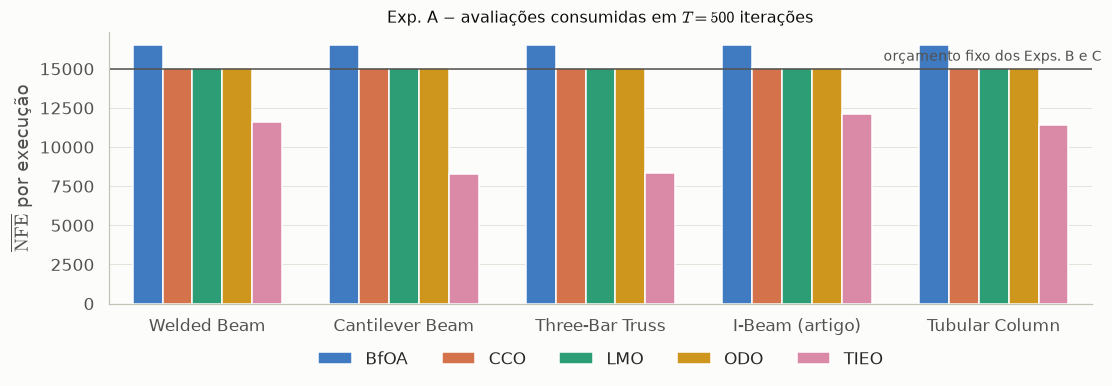

In [14]:
nfe_long = nfe_A.reset_index().melt(id_vars="problem", var_name="Algoritmo", value_name="NFE_medio")

fig, ax = plt.subplots(figsize=(10, 3.4))
sns.barplot(
    data=nfe_long, x="problem", y="NFE_medio", hue="Algoritmo",
    hue_order=ALG_NAMES, palette=COLORS, ax=ax,
    width=0.76, dodge=True,
)
ax.axhline(NFE_MAX, color=INK2, lw=1)
ax.text(len(PROBS_ART) - 0.45, NFE_MAX * 1.02,
        r"orçamento fixo dos Exps. B e C",
        ha="right", va="bottom", color=INK2, fontsize=9)
ax.set(
    ylabel=r"$\overline{\mathrm{NFE}}$ por execução",
    title=fr"Exp. A $-$ avaliações consumidas em $T = {MAX_ITER}$ iterações",
    xlabel="",
)
ax.grid(axis="x", visible=False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.savefig(FIGS / "fig_exp_a_nfe.pdf", bbox_inches="tight")
plt.show()


Resultados por problema, com a média e a melhor solução reportadas no artigo ao lado. A coluna *Viável* indica a porcentagem de execuções cuja melhor solução satisfaz todas as restrições ($\max_i g_i\le10^{-8}$) — informação ausente no artigo.

In [15]:
for p in PROBS_ART:
    display(problem_table(A, p, article=True))

,Tempo (s),NFE,Média,Média (artigo),DP,Melhor,Melhor (artigo),Pior,Viável (%),h,l,t,b
Welded Beam,,,,,,,,,,,,,
BfOA,0.590,"16,500",1.747839,3.4522,4.64e-02,1.726157,2.4422,1.935156,100,0.2056,3.4760,9.0393,0.2058
CCO,1.318,"15,030",1.724893,1.8976,8.27e-05,1.724852,1.7286,1.725185,100,0.2057,3.4705,9.0366,0.2057
LMO,0.166,"15,030",1.746621,1.370e+12,1.46e-02,1.729843,3.3616,1.780586,100,0.2039,3.5168,9.0410,0.2058
ODO,0.181,"15,030",1.813251,1.8918,1.27e-01,1.724855,1.7249,2.288478,100,0.2057,3.4705,9.0366,0.2057
TIEO,0.908,"11,614",1.91894,1.7947,2.29e-01,1.72497,1.7249,2.564064,100,0.2057,3.4717,9.0368,0.2057


,Tempo (s),NFE,Média,Média (artigo),DP,Melhor,Melhor (artigo),Pior,Viável (%),x1,x2,x3,x4,x5
Cantilever Beam,,,,,,,,,,,,,,
BfOA,0.392,"16,500",1.34029,1.7013,1.61e-04,1.340026,1.5151,1.340634,100,6.0270,5.3325,4.4599,3.5068,2.1485
CCO,1.216,"15,030",1.339964,1.3444,6.76e-06,1.339958,1.3401,1.339982,100,6.0146,5.3095,4.4936,3.4992,2.1567
LMO,0.115,"15,030",1.342529,1.3425,1.67e-03,1.340524,1.3405,1.34673,100,6.0840,5.2855,4.4449,3.4508,2.2175
ODO,0.136,"15,030",1.339985,1.34,1.79e-05,1.33996,1.34,1.340037,100,6.0139,5.3119,4.4938,3.5045,2.1496
TIEO,0.653,"8,302",1.340101,1.342,1.08e-04,1.339975,1.34,1.34046,100,6.0348,5.3090,4.4771,3.5036,2.1494


,Tempo (s),NFE,Média,Média (artigo),DP,Melhor,Melhor (artigo),Pior,Viável (%),A1,A2
Three-Bar Truss,,,,,,,,,,,
BfOA,0.421,"16,500",263.897,264.9324,2.18e-03,263.8959,263.8958,263.9068,100,0.7888,0.4079
CCO,1.267,"15,030",263.8958,263.9083,9.96e-07,263.8958,263.8958,263.8958,100,0.7887,0.4083
LMO,0.123,"15,030",263.902,281.8089,4.62e-03,263.8969,266.8859,263.9141,100,0.7895,0.4060
ODO,0.140,"15,030",263.8963,263.8963,5.67e-04,263.8959,263.8958,263.8984,100,0.7886,0.4086
TIEO,0.667,"8,334",263.8973,263.9037,1.85e-03,263.8958,263.8958,263.9022,100,0.7886,0.4084


,Tempo (s),NFE,Média,Média (artigo),DP,Melhor,Melhor (artigo),Pior,Viável (%),b,h,tw,tf
I-Beam (artigo),,,,,,,,,,,,,
BfOA,0.485,"16,500",0.01492903,0.0153,7.83e-07,0.01492781,0.0149,0.01493061,100,50.0000,80.0000,1.5524,1.8143
CCO,1.297,"15,030",0.01492713,0.0149,1.62e-12,0.01492713,0.0149,0.01492713,100,50.0000,80.0000,1.5524,1.8144
LMO,0.139,"15,030",0.01493515,7.910e+15,5.38e-06,0.01492903,0.0295,0.01495317,100,50.0000,79.9998,1.5529,1.8140
ODO,0.159,"15,030",0.01492713,0.0149,2.74e-09,0.01492713,0.0149,0.01492715,100,50.0000,80.0000,1.5524,1.8144
TIEO,0.848,"12,120",0.01543482,0.0149,1.39e-03,0.01492713,0.0149,0.02096853,100,50.0000,80.0000,1.5524,1.8144


,Tempo (s),NFE,Média,Média (artigo),DP,Melhor,Melhor (artigo),Pior,Viável (%),d,t
Tubular Column,,,,,,,,,,,
BfOA,0.472,"16,500",26.50058,26.5679,5.92e-04,26.49974,26.4995,26.50199,100,5.4512,0.2920
CCO,1.269,"15,030",26.4995,26.4995,2.98e-09,26.4995,26.4995,26.4995,100,5.4512,0.2920
LMO,0.135,"15,030",26.50423,31.7051,2.57e-03,26.50017,27.9884,26.51032,100,5.4512,0.2920
ODO,0.154,"15,030",26.4995,26.4995,6.08e-15,26.4995,26.4995,26.4995,100,5.4512,0.2920
TIEO,0.773,"11,409",26.4995,26.4995,1.07e-07,26.4995,26.4995,26.4995,100,5.4512,0.2920


In [16]:
R_A_art = ranks(A, "artigo")
fr_A_art = friedman(R_A_art)
display(pd.concat([R_A_art, R_A_art.mean().rename("Ranking médio").to_frame().T,
                   ARTIGO_RANK.rename("Ranking médio (artigo)").to_frame().T]).round(2))
print(friedman_text(fr_A_art, "Exp. A, ranking do artigo — "))

,BfOA,CCO,LMO,ODO,TIEO
Welded Beam,3.0,1.0,2.0,4.0,5.0
Cantilever Beam,4.0,1.0,5.0,2.0,3.0
Three-Bar Truss,3.0,1.0,5.0,2.0,4.0
I-Beam (artigo),3.0,1.0,4.0,2.0,5.0
Tubular Column,4.0,2.0,5.0,1.0,3.0
Ranking médio,3.4,1.2,4.2,2.2,4.0
Ranking médio (artigo),4.2,3.2,4.6,1.4,1.6


Exp. A, ranking do artigo — N = 5, k = 5: χ²_F = 12.96 (p = 0.0115); F_ID = 7.36 (p = 0.0015); CD = 2.728. Pares significativos (Nemenyi): CCO–LMO, CCO–TIEO.


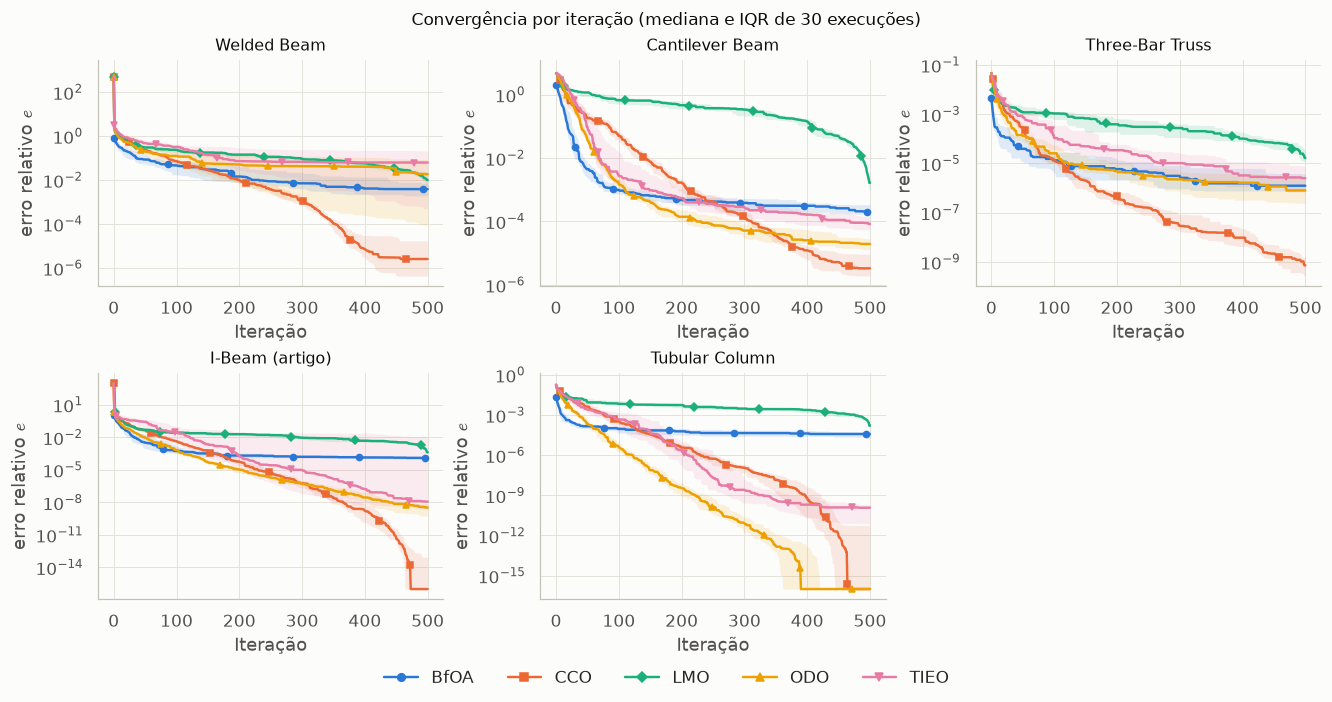

In [17]:
plot_convergence(A, by="iter", title=f"Convergência por iteração (mediana e IQR de {RUNS} execuções)")

## 6. Experimento B — orçamento de NFE equalizado

Todos os algoritmos param em $NFE_{\max}=15\,000$ avaliações (incluindo as 2000 do reconhecimento do BfOA), com os cronogramas internos indexados por $p=NFE/NFE_{\max}$. Problemas, parâmetros e penalidade são os do Exp. A.

In [18]:
B = experiment("B_nfe_fixo", configs(PROBS_ART))
for p in PROBS_ART:
    display(problem_table(B, p))

,Tempo (s),NFE,Média,DP,Melhor,Pior,Viável (%),h,l,t,b
Welded Beam,,,,,,,,,,,
BfOA,0.550,"15,000",1.74908,4.61e-02,1.726157,1.935193,100,0.2056,3.4760,9.0393,0.2058
CCO,1.343,"15,000",1.724893,8.27e-05,1.724852,1.725185,100,0.2057,3.4705,9.0366,0.2057
LMO,0.170,"15,000",1.746621,1.46e-02,1.729843,1.780586,100,0.2039,3.5168,9.0410,0.2058
ODO,0.185,"15,000",1.81372,1.27e-01,1.724855,2.288478,100,0.2057,3.4705,9.0366,0.2057
TIEO,1.231,"15,000",1.90119,2.14e-01,1.724854,2.560783,100,0.2057,3.4705,9.0366,0.2057


,Tempo (s),NFE,Média,DP,Melhor,Pior,Viável (%),x1,x2,x3,x4,x5
Cantilever Beam,,,,,,,,,,,,
BfOA,0.361,"15,000",1.340317,1.65e-04,1.340026,1.340634,100,6.0270,5.3325,4.4599,3.5068,2.1485
CCO,1.279,"15,000",1.339964,6.76e-06,1.339958,1.339982,100,6.0146,5.3095,4.4936,3.4992,2.1567
LMO,0.120,"15,000",1.342529,1.67e-03,1.340524,1.34673,100,6.0840,5.2855,4.4449,3.4508,2.2175
ODO,0.144,"15,000",1.339985,1.78e-05,1.33996,1.340037,100,6.0139,5.3119,4.4938,3.5045,2.1496
TIEO,1.388,"15,000",1.339992,2.42e-05,1.339962,1.340065,100,6.0206,5.3051,4.4888,3.5045,2.1548


,Tempo (s),NFE,Média,DP,Melhor,Pior,Viável (%),A1,A2
Three-Bar Truss,,,,,,,,,
BfOA,0.398,"15,000",263.8973,2.55e-03,263.8959,263.9068,100,0.7888,0.4079
CCO,1.295,"15,000",263.8958,9.96e-07,263.8958,263.8958,100,0.7887,0.4083
LMO,0.125,"15,000",263.902,4.62e-03,263.8969,263.9141,100,0.7895,0.4060
ODO,0.142,"15,000",263.8963,5.67e-04,263.8959,263.8984,100,0.7886,0.4086
TIEO,1.348,"15,000",263.8965,1.11e-03,263.8958,263.9004,100,0.7886,0.4084


,Tempo (s),NFE,Média,DP,Melhor,Pior,Viável (%),b,h,tw,tf
I-Beam (artigo),,,,,,,,,,,
BfOA,0.458,"15,000",0.01492922,9.31e-07,0.01492781,0.01493179,100,50.0000,80.0000,1.5524,1.8143
CCO,1.317,"15,000",0.01492713,1.62e-12,0.01492713,0.01492713,100,50.0000,80.0000,1.5524,1.8144
LMO,0.144,"15,000",0.01493515,5.38e-06,0.01492903,0.01495317,100,50.0000,79.9998,1.5529,1.8140
ODO,0.167,"15,000",0.01492713,2.74e-09,0.01492713,0.01492715,100,50.0000,80.0000,1.5524,1.8144
TIEO,1.094,"15,000",0.01537011,1.30e-03,0.01492713,0.02057079,100,50.0000,80.0000,1.5524,1.8144


,Tempo (s),NFE,Média,DP,Melhor,Pior,Viável (%),d,t
Tubular Column,,,,,,,,,
BfOA,0.440,"15,000",26.50059,5.98e-04,26.49974,26.50199,100,5.4512,0.2920
CCO,1.326,"15,000",26.4995,2.98e-09,26.4995,26.4995,100,5.4512,0.2920
LMO,0.141,"15,000",26.50423,2.57e-03,26.50017,26.51032,100,5.4512,0.2920
ODO,0.157,"15,000",26.4995,6.08e-15,26.4995,26.4995,100,5.4512,0.2920
TIEO,1.104,"15,000",26.4995,1.34e-08,26.4995,26.4995,100,5.4512,0.2920


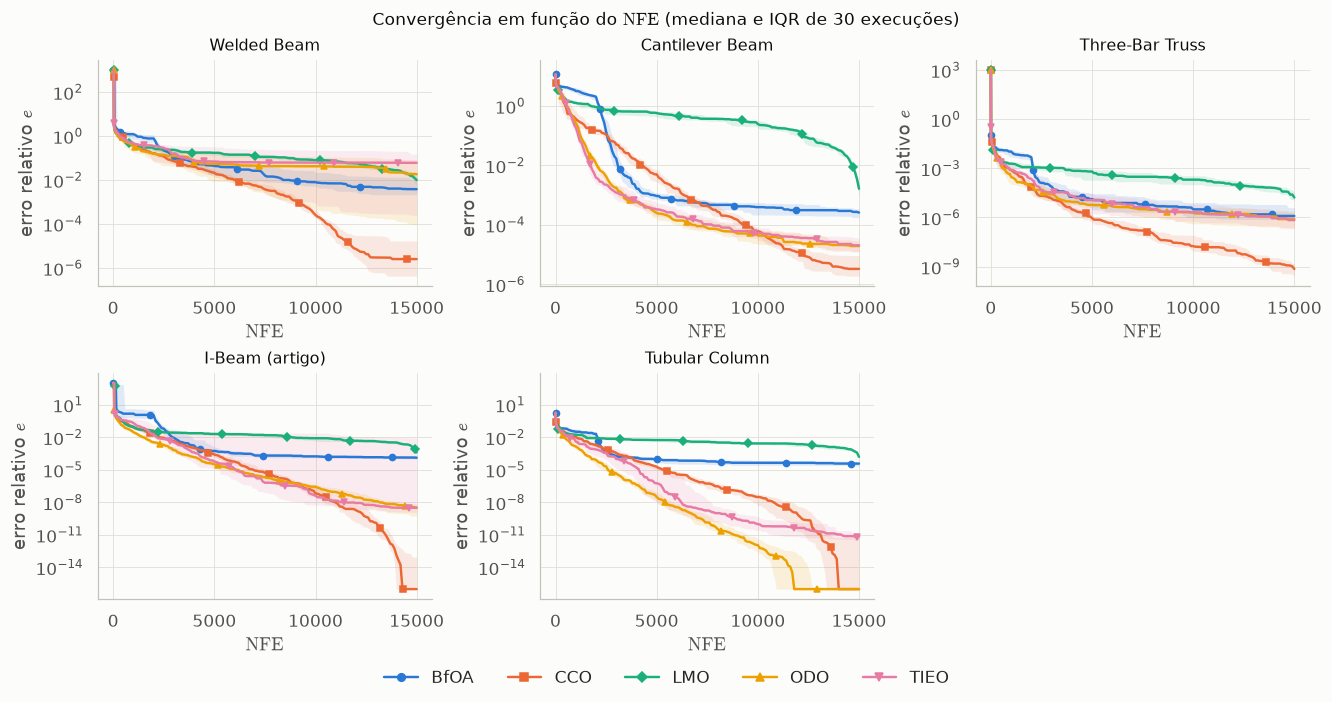

<positron-console-cell-19>:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<positron-console-cell-19>:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<positron-console-cell-19>:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<positron-console-cell-19>:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<positron-console-cell-19>:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign t

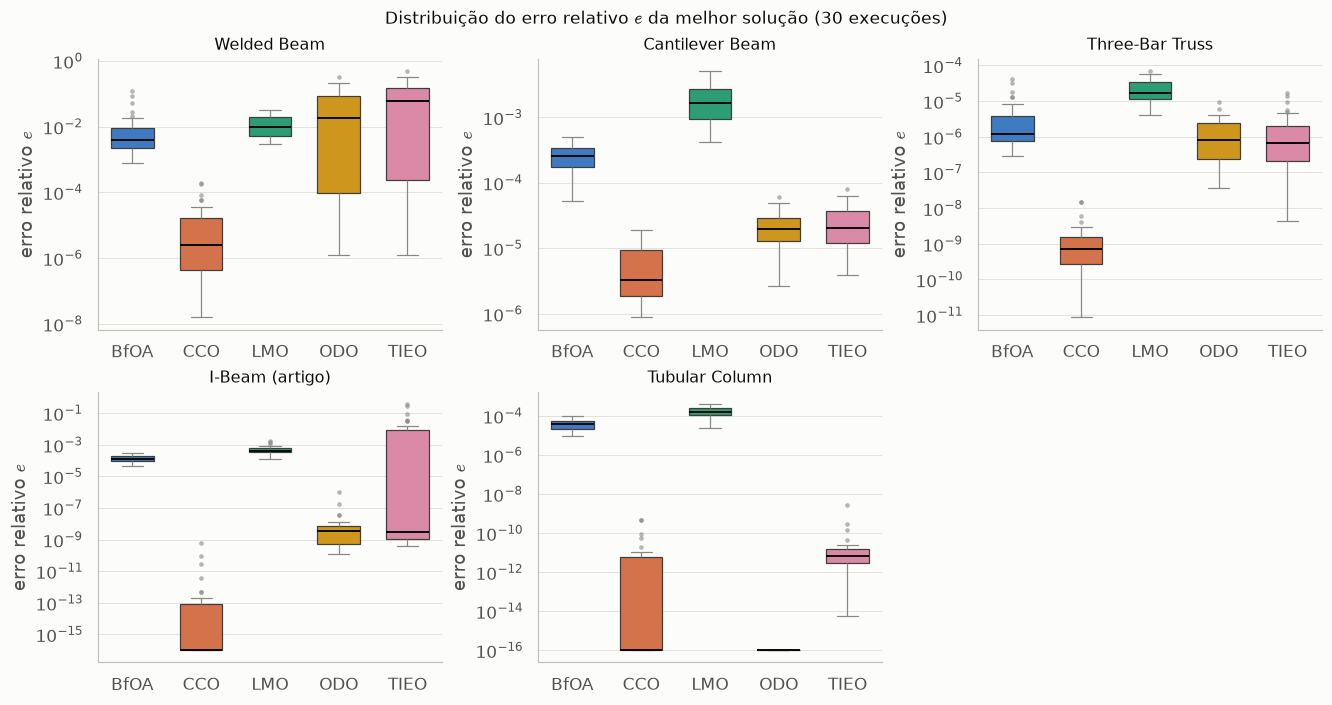

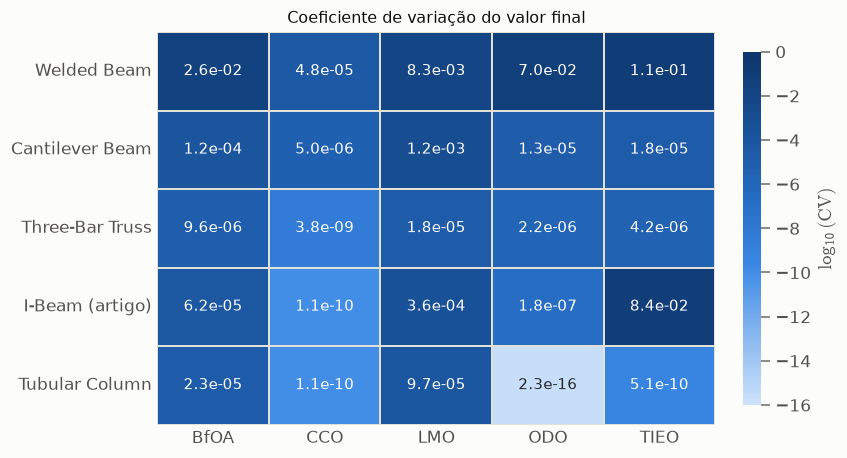

In [19]:
plot_convergence(B, title=fr"Convergência em função do $\mathrm{{NFE}}$ (mediana e IQR de {RUNS} execuções)")
plot_box(B, title=fr"Distribuição do erro relativo $e$ da melhor solução ({RUNS} execuções)")
plot_cv(B, title=r"Coeficiente de variação do valor final")


,BfOA,CCO,LMO,ODO,TIEO
Artigo,4.2,3.2,4.6,1.4,1.6
Exp. A (critério do artigo),3.4,1.2,4.2,2.2,4.0
Exp. B (critério do artigo),3.6,1.2,4.2,2.2,3.8
Exp. B (com tolerância),3.6,1.2,4.2,2.4,3.6


alg,BfOA,CCO,LMO,ODO,TIEO
problem,,,,,
Welded Beam,3.0,1.0,2.0,4.0,5.0
Cantilever Beam,4.0,1.0,5.0,2.0,3.0
Three-Bar Truss,4.0,1.0,5.0,2.0,3.0
I-Beam (artigo),3.0,1.0,4.0,2.0,5.0
Tubular Column,4.0,2.0,5.0,2.0,2.0


Exp. B, ranking do artigo — N = 5, k = 5: χ²_F = 12.64 (p = 0.0132); F_ID = 6.87 (p = 0.0020); CD = 2.728. Pares significativos (Nemenyi): CCO–LMO.
Exp. B, ranking com tolerância — N = 5, k = 5: χ²_F = 12.00 (p = 0.0174); F_ID = 6.00 (p = 0.0038); CD = 2.728. Pares significativos (Nemenyi): CCO–LMO.


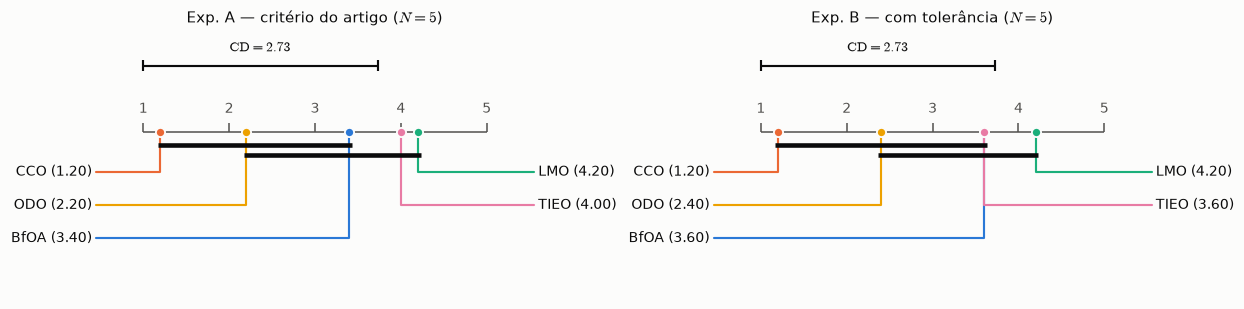

In [20]:
R_B_art, R_B = ranks(B, "artigo"), ranks(B)
fr_B_art, fr_B = friedman(R_B_art), friedman(R_B)
cmp = pd.DataFrame({"Artigo": ARTIGO_RANK, "Exp. A (critério do artigo)": R_A_art.mean(),
                    "Exp. B (critério do artigo)": R_B_art.mean(), "Exp. B (com tolerância)": R_B.mean()})
display(cmp.T[ALG_NAMES].round(2))
display(R_B.round(1))
print(friedman_text(fr_B_art, "Exp. B, ranking do artigo — "))
print(friedman_text(fr_B, "Exp. B, ranking com tolerância — "))
plot_cd({"Exp. A — critério do artigo": fr_A_art, "Exp. B — com tolerância": fr_B})

## 7. Melhorias metodológicas (Exp. C)

### 7.1 Viabilidade das soluções reportadas

O artigo afirma que soluções inviáveis "tendem a ser penalizadas", mas não verifica se as melhores soluções finais são viáveis. A tabela abaixo reporta, para os Exps. A e B, a porcentagem de execuções com solução final viável e a maior violação observada entre as melhores soluções.

In [21]:
feas = pd.concat({lab: df.groupby(["problem", "alg"], sort=False).agg(v=("feasible", "mean"), g=("gmax", "max"))
                  for lab, df in {"Exp. A": A, "Exp. B": B}.items()}, axis=1)
viav = pd.concat({lab: (100 * feas[(lab, "v")]).unstack().loc[PROBS_ART, ALG_NAMES] for lab in ("Exp. A", "Exp. B")}, axis=1)
viol = pd.concat({lab: feas[(lab, "g")].unstack().loc[PROBS_ART, ALG_NAMES] for lab in ("Exp. A", "Exp. B")}, axis=1)
display(viav.map("{:.0f} %".format))
display(viol.map(lambda v: f"{v:.1e}"))

Exp. A                             Exp. B                            
alg               BfOA    CCO    LMO    ODO   TIEO   BfOA    CCO    LMO    ODO   TIEO
problem                                                                              
Welded Beam      100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %
Cantilever Beam  100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %
Three-Bar Truss  100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %
I-Beam (artigo)  100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %
Tubular Column   100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %  100 %

Exp. A                                           Exp. B                                       
alg                  BfOA      CCO       LMO       ODO      TIEO      BfOA      CCO       LMO       ODO      TIEO
problem                                                                                                          
Welded Beam      -1.9e-05  1.1e-15  -1.6e-05  -8.1e-09  -5.8e-08  -6.3e-06  1.1e-15  -1.6e-05  -8.1e-09  -2.0e-09
Cantilever Beam  -1.6e-05  4.4e-16  -4.1e-05  -6.0e-07  -9.8e-07  -1.6e-05  4.4e-16  -4.1e-05  -6.0e-07  -3.4e-07
Three-Bar Truss  -2.4e-09  7.7e-13  -7.6e-07   1.5e-13  -7.0e-12  -2.4e-09  7.7e-13  -7.6e-07   1.5e-13   9.6e-13
I-Beam (artigo)  -7.4e-07  0.0e+00  -2.9e-06  -1.0e-14  -2.2e-11  -7.4e-07  0.0e+00  -2.9e-06  -1.0e-14  -7.2e-13
Tubular Column   -6.2e-07  1.2e-14  -1.3e-05   8.0e-15   6.4e-13  -6.2e-07  1.2e-14  -1.3e-05   8.0e-15   2.3e-13

### 7.2 Regras de Deb × penalidade estática no conjunto ampliado

O Exp. C usa 8 problemas (o I-Beam passa à formulação corrigida e entram Pressure Vessel, Spring e Speed Reducer), $NFE_{\max}=15\,000$ e 30 execuções, comparando a penalidade com $\lambda=10^{15}$ às regras de Deb. Com $N=8$ a diferença crítica de Nemenyi cai de 2,73 para 2,16, aumentando o poder do teste.

In [22]:
C_pen = experiment("C_penalidade", configs(PROBS_EXT))
C_deb = experiment("C_deb", configs(PROBS_EXT, handler="deb"))
SC = {"Penalidade λ=1e15": summary(C_pen), "Regras de Deb": summary(C_deb)}
med_err = pd.concat({k: s["Erro mediano"].unstack().loc[PROBS_EXT, ALG_NAMES] for k, s in SC.items()}, axis=1)
mean_err = pd.concat({k: s["Erro médio"].unstack().loc[PROBS_EXT, ALG_NAMES] for k, s in SC.items()}, axis=1)
viav_C = pd.concat({k: s["Viável (%)"].unstack().loc[PROBS_EXT, ALG_NAMES] for k, s in SC.items()}, axis=1)
print("Erro relativo mediano")
display(med_err.map(lambda v: f"{v:.1e}"))
print("Erro relativo médio")
display(mean_err.map(lambda v: f"{v:.1e}"))
print("Execuções com solução final viável")
display(viav_C.map("{:.0f} %".format))

Erro relativo mediano


Penalidade λ=1e15                                       Regras de Deb                                      
alg                          BfOA       CCO      LMO       ODO     TIEO          BfOA       CCO      LMO       ODO     TIEO
problem                                                                                                                    
Welded Beam               3.8e-03   2.5e-06  9.9e-03   1.8e-02  6.0e-02       3.8e-03   3.6e-06  1.4e-02   2.9e-02  4.7e-02
Cantilever Beam           2.6e-04   3.3e-06  1.6e-03   1.9e-05  2.0e-05       2.6e-04   3.3e-06  1.6e-03   1.9e-05  3.3e-05
Three-Bar Truss           1.2e-06   7.1e-10  1.7e-05   7.9e-07  6.9e-07       1.2e-06   6.1e-10  1.8e-05   8.4e-07  3.5e-07
I-Beam                    8.6e-06  -1.0e-13  4.2e-05  -1.0e-13  7.8e-13       1.0e-05  -1.0e-13  2.6e-05  -1.0e-13  1.0e-11
Tubular Column            3.7e-05  -3.7e-14  1.6e-04  -3.8e-14  6.9e-12       3.7e-05   3.2e-14  1.6e-04  -3.6e-14  2.5e-11
Pressure Vessel           1.3e-01   7.5e-05  1.4e-01   8.2e-02  5.8e-02       1.3e-01   7.5e-05  1.4e-01   7.7e-02  4.7e-02
Spring                    8.6e-02   1.3e-04  5.9e-03   1.6e-02  9.4e-03       8.6e-02   1.5e-04  5.8e-03   1.2e-02  1.1e-02
Speed Reducer             3.6e-03   3.0e-11  3.4e-03  -3.8e-13  1.8e-08       3.7e-03   1.8e-10  2.6e-03  -9.8e-14  9.0e-09

Erro relativo médio


Penalidade λ=1e15                                      Regras de Deb                                     
alg                          BfOA      CCO      LMO       ODO     TIEO          BfOA      CCO      LMO       ODO     TIEO
problem                                                                                                                  
Welded Beam               1.4e-02  2.4e-05  1.3e-02   5.2e-02  1.0e-01       1.3e-02  2.1e-05  1.3e-02   7.8e-02  1.5e-01
Cantilever Beam           2.7e-04  5.7e-06  1.9e-03   2.2e-05  2.6e-05       2.7e-04  5.7e-06  1.9e-03   2.2e-05  4.1e-05
Three-Bar Truss           5.4e-06  2.1e-09  2.4e-05   1.7e-06  2.5e-06       5.4e-06  1.9e-09  2.4e-05   2.0e-06  9.3e-07
I-Beam                    1.6e-05  9.4e-13  6.5e-05   9.3e-15  3.1e-03       2.1e-05  1.9e-11  5.7e-05  -1.0e-13  2.7e-03
Tubular Column            4.1e-05  3.6e-11  1.8e-04  -3.8e-14  1.2e-10       4.1e-05  9.4e-12  1.8e-04  -2.5e-14  6.0e-06
Pressure Vessel           1.2e-01  4.2e-04  1.6e-01   9.9e-02  5.9e-02       1.2e-01  4.8e-04  1.6e-01   9.7e-02  6.6e-02
Spring                    1.0e-01  3.3e-04  1.3e-02   4.8e-02  4.5e-02       9.9e-02  1.9e-04  1.2e-02   3.1e-02  4.6e-02
Speed Reducer             3.7e-03  2.6e-09  3.5e-03  -3.8e-13  5.7e-04       3.7e-03  2.1e-09  3.0e-03  -9.8e-14  5.8e-04

Execuções com solução final viável


Penalidade λ=1e15                             Regras de Deb                            
alg                          BfOA    CCO    LMO    ODO   TIEO          BfOA    CCO    LMO    ODO   TIEO
problem                                                                                                
Welded Beam                 100 %  100 %  100 %  100 %  100 %         100 %  100 %  100 %  100 %  100 %
Cantilever Beam             100 %  100 %  100 %  100 %  100 %         100 %  100 %  100 %  100 %  100 %
Three-Bar Truss             100 %  100 %  100 %  100 %  100 %         100 %  100 %  100 %  100 %  100 %
I-Beam                      100 %  100 %  100 %  100 %  100 %         100 %  100 %  100 %  100 %  100 %
Tubular Column              100 %  100 %  100 %  100 %  100 %         100 %  100 %  100 %  100 %  100 %
Pressure Vessel             100 %  100 %  100 %  100 %  100 %         100 %  100 %  100 %  100 %  100 %
Spring                      100 %  100 %  100 %  100 %  100 %         100 %  100 %  100 %  100 %  100 %
Speed Reducer               100 %  100 %  100 %  100 %  100 %         100 %  100 %  100 %  100 %  100 %

Penalidade                      Deb                    
alg                   BfOA  CCO  LMO  ODO TIEO BfOA  CCO  LMO  ODO TIEO
problem                                                                
Welded Beam            3.0  1.0  2.0  4.0  5.0  3.0  1.0  2.0  4.0  5.0
Cantilever Beam        4.0  1.0  5.0  2.0  3.0  4.0  1.0  5.0  2.0  3.0
Three-Bar Truss        4.0  1.0  5.0  2.0  3.0  4.0  1.0  5.0  3.0  2.0
I-Beam                 3.0  1.5  4.0  1.5  5.0  3.0  1.5  4.0  1.5  5.0
Tubular Column         4.0  2.0  5.0  2.0  2.0  4.0  1.5  5.0  1.5  3.0
Pressure Vessel        4.0  1.0  5.0  3.0  2.0  4.0  1.0  5.0  3.0  2.0
Spring                 5.0  1.0  2.0  4.0  3.0  5.0  1.0  2.0  3.0  4.0
Speed Reducer          5.0  1.5  4.0  1.5  3.0  5.0  1.5  4.0  1.5  3.0

alg,BfOA,CCO,LMO,ODO,TIEO
Penalidade,4.0,1.25,4.0,2.50,3.25
Deb,4.0,1.19,4.0,2.44,3.38


Penalidade — N = 8, k = 5: χ²_F = 17.87 (p = 0.0013); F_ID = 8.85 (p = 0.0001); CD = 2.157. Pares significativos (Nemenyi): BfOA–CCO, CCO–LMO.
Deb — N = 8, k = 5: χ²_F = 18.73 (p = 0.0009); F_ID = 9.88 (p = 0.0000); CD = 2.157. Pares significativos (Nemenyi): BfOA–CCO, CCO–LMO, CCO–TIEO.


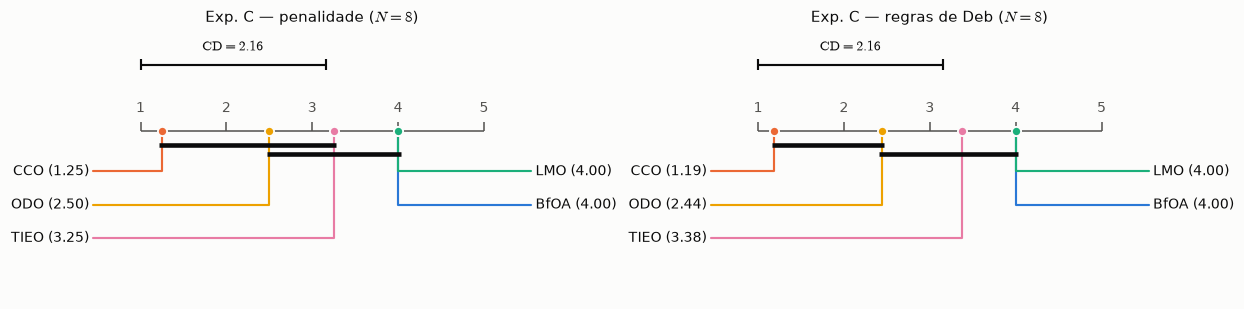

In [23]:
R_pen, R_deb = ranks(C_pen), ranks(C_deb)
fr_pen, fr_deb = friedman(R_pen), friedman(R_deb)
display(pd.concat({"Penalidade": R_pen, "Deb": R_deb}, axis=1).round(1))
display(pd.DataFrame({"Penalidade": fr_pen["Rbar"], "Deb": fr_deb["Rbar"]}).T[ALG_NAMES].round(2))
print(friedman_text(fr_pen, "Penalidade — "))
print(friedman_text(fr_deb, "Deb — "))
plot_cd({"Exp. C — penalidade": fr_pen, "Exp. C — regras de Deb": fr_deb})

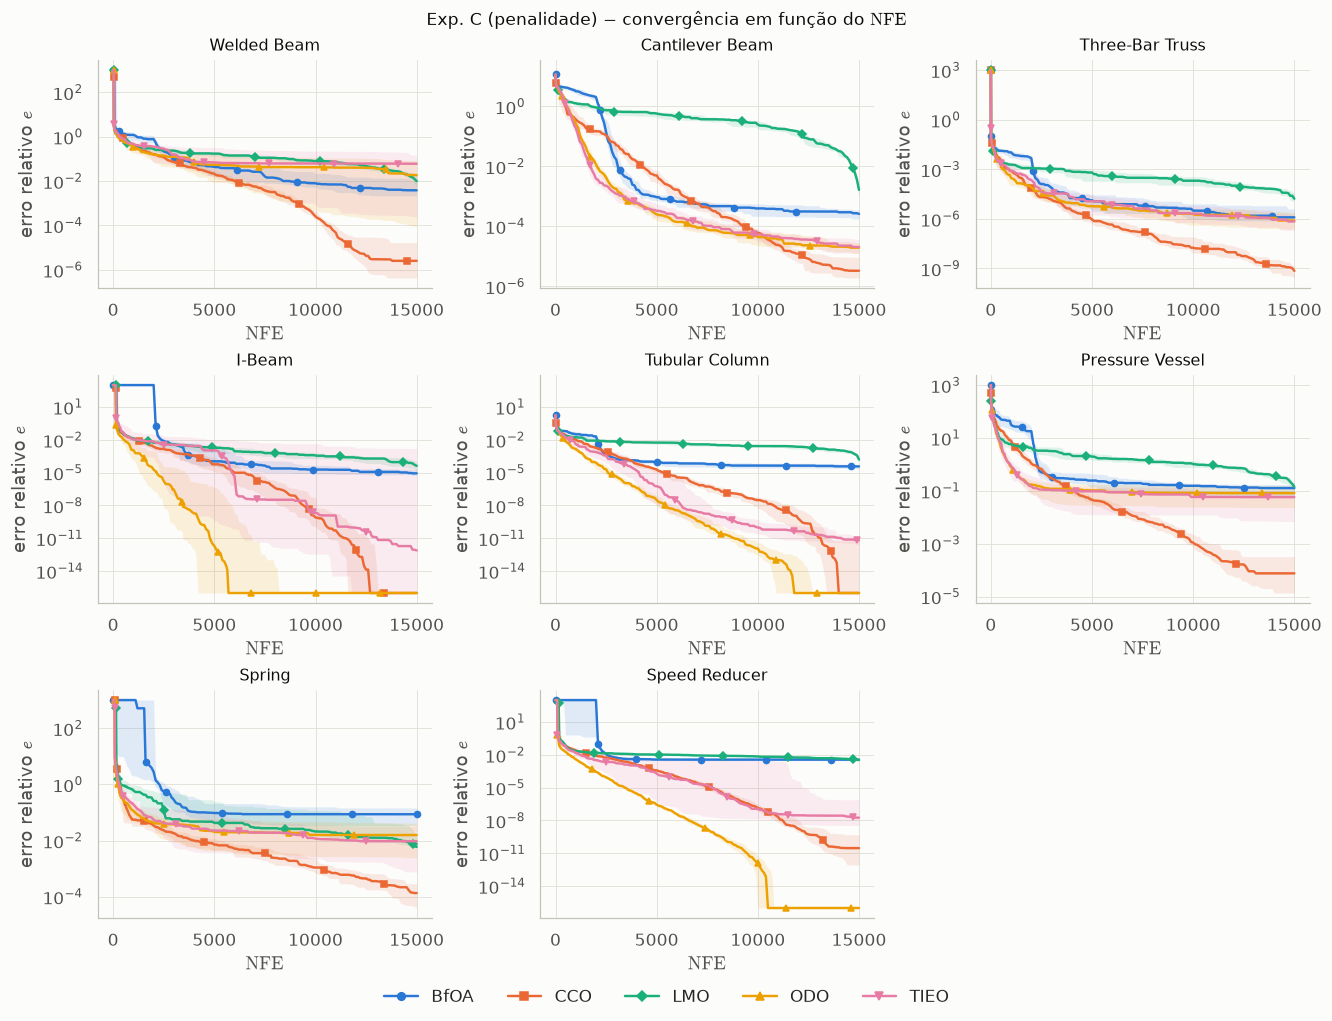

<positron-console-cell-24>:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<positron-console-cell-24>:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<positron-console-cell-24>:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<positron-console-cell-24>:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<positron-console-cell-24>:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign t

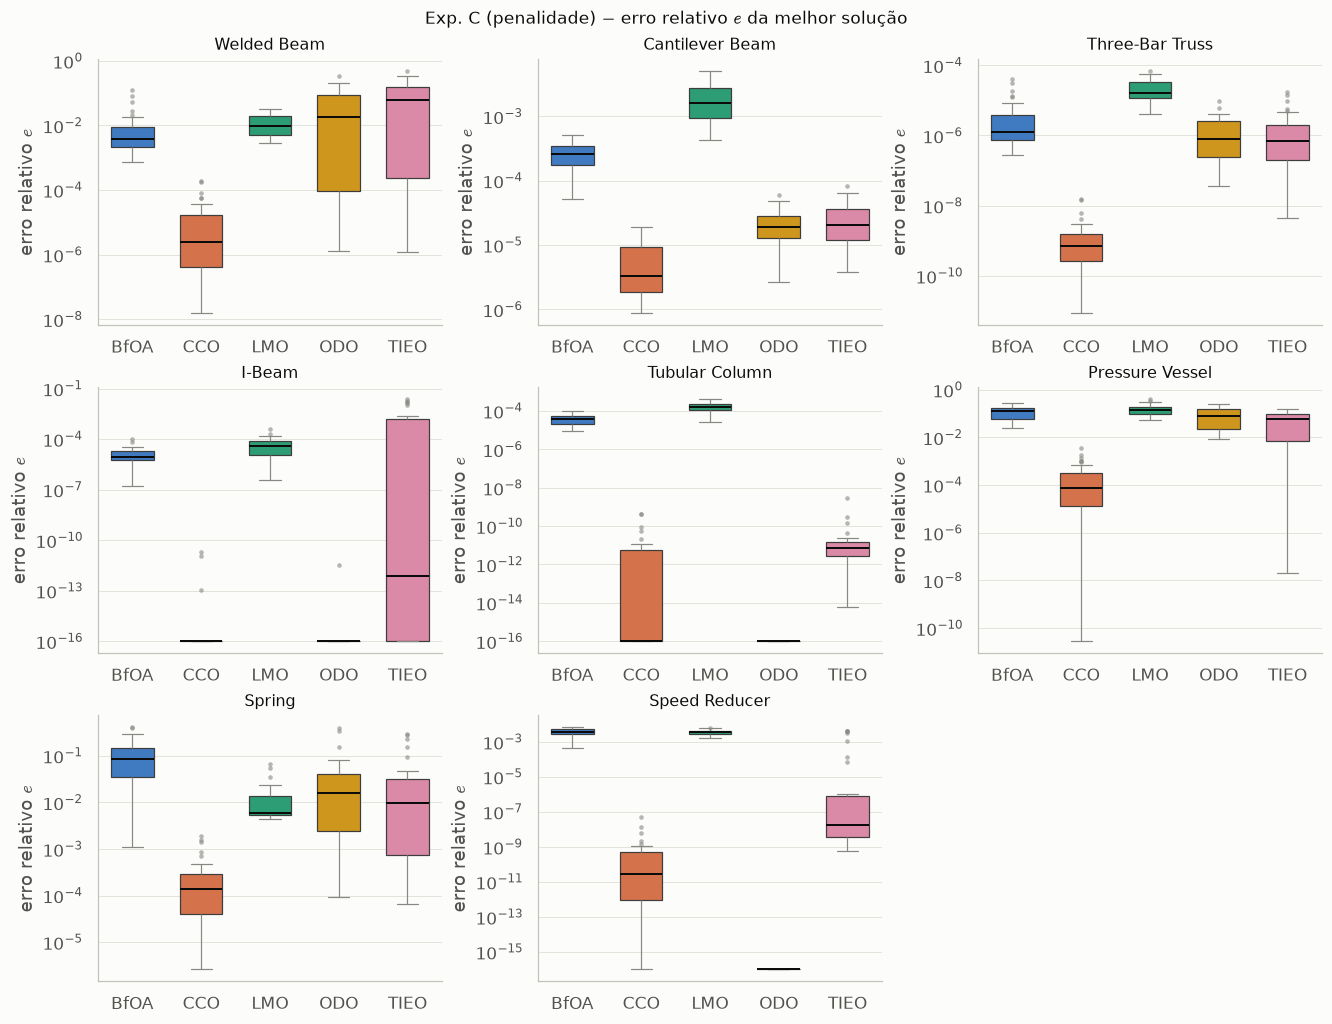

In [24]:
plot_convergence(C_pen, title=r"Exp. C (penalidade) $-$ convergência em função do $\mathrm{NFE}$")
plot_box(C_pen, title=r"Exp. C (penalidade) $-$ erro relativo $e$ da melhor solução")


### 7.3 Comparações por pares com Mann–Whitney e Holm

Com 30 execuções por algoritmo, cada problema permite testar os pares diretamente, sem depender de apenas $N$ médias. Cada célula conta, ao longo dos 8 problemas, em quantos o algoritmo da linha foi significativamente melhor (V), indistinguível (E) ou pior (D) que o da coluna ($\alpha=0{,}05$ após Holm).

In [25]:
print("Penalidade")
display(wtl(C_pen))
print("Regras de Deb")
display(wtl(C_deb))

Penalidade


,BfOA,CCO,LMO,ODO,TIEO,Saldo (V−D)
linha vs coluna: V/E/D,,,,,,
BfOA,—,0/0/8,5/2/1,0/3/5,0/2/6,-15
CCO,8/0/0,—,8/0/0,5/3/0,7/1/0,28
LMO,1/2/5,0/0/8,—,0/2/6,0/2/6,-24
ODO,5/3/0,0/3/5,6/2/0,—,2/6/0,8
TIEO,6/2/0,0/1/7,6/2/0,0/6/2,—,3


Regras de Deb


,BfOA,CCO,LMO,ODO,TIEO,Saldo (V−D)
linha vs coluna: V/E/D,,,,,,
BfOA,—,0/0/8,5/2/1,0/3/5,0/1/7,-16
CCO,8/0/0,—,8/0/0,5/3/0,7/1/0,28
LMO,1/2/5,0/0/8,—,0/2/6,0/2/6,-24
ODO,5/3/0,0/3/5,6/2/0,—,3/5/0,9
TIEO,7/1/0,0/1/7,6/2/0,0/5/3,—,3


### 7.4 Desempenho em todos os orçamentos (ECDF)

Cada curva mostra a fração dos $8\times30\times8$ pares (problema, execução, alvo) já resolvidos após cada NFE, com alvos de erro relativo de $10^{-1}$ a $10^{-8}$. Uma curva acima da outra em toda a extensão indica superioridade para qualquer orçamento; cruzamentos indicam que o vencedor depende do orçamento disponível.

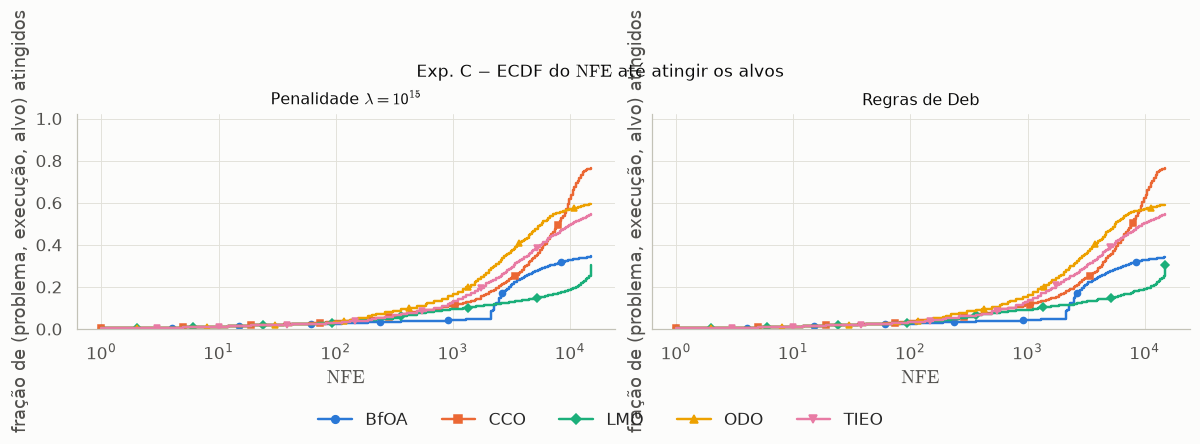

In [26]:
plot_ecdf(
    {r"Penalidade $\lambda=10^{15}$": C_pen, "Regras de Deb": C_deb},
    title=r"Exp. C $-$ ECDF do $\mathrm{NFE}$ até atingir os alvos",
)


### 7.5 Sensibilidade ao coeficiente de penalidade

Quatro problemas com restrições ativas não lineares, $\lambda\in\{10,\,10^4,\,10^8,\,10^{15}\}$ e 15 execuções. Mostra-se a fração de soluções finais viáveis e o erro relativo **do objetivo sem penalidade**, $(f-f^*)/|f^*|$: valores negativos indicam soluções inviáveis que "superam" o ótimo.

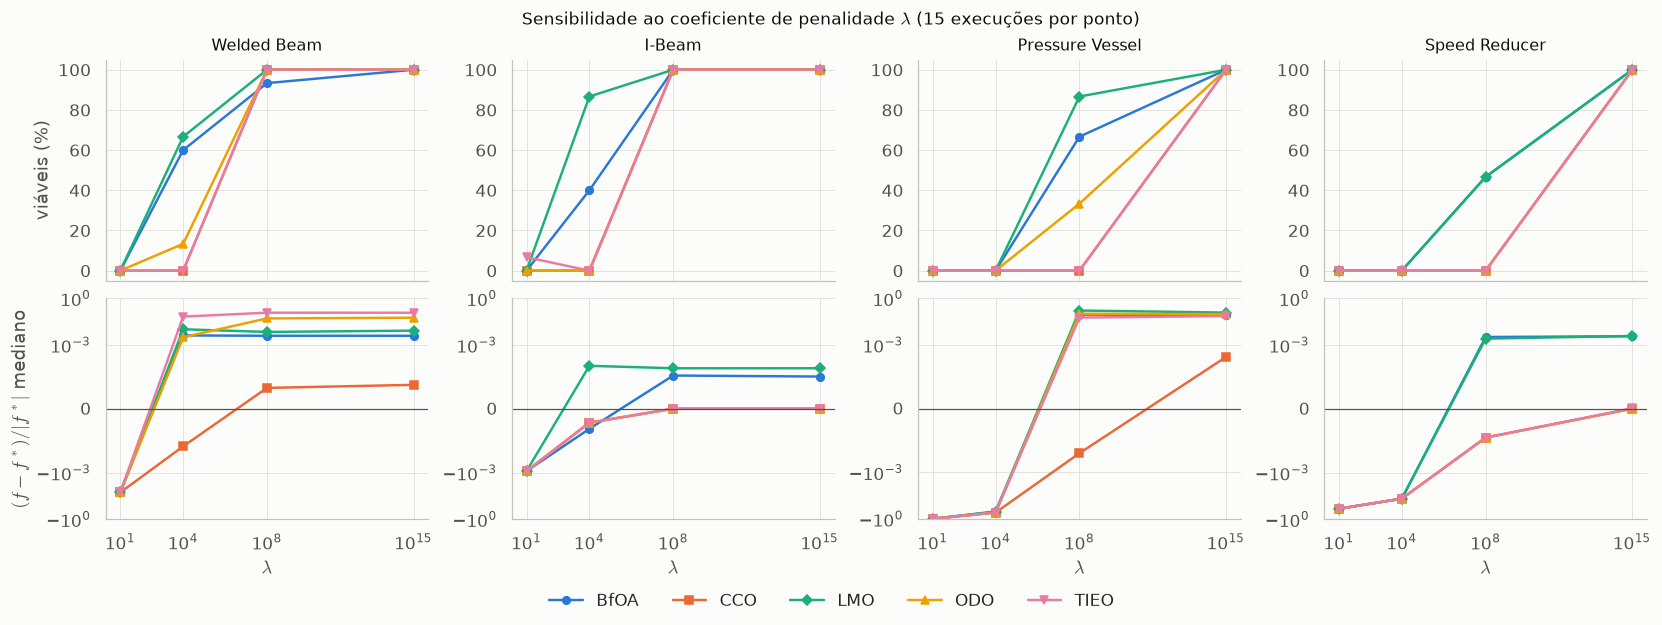

alg                            BfOA    CCO    LMO    ODO   TIEO
problem         lam                                            
Welded Beam     1.000000e+01    0 %    0 %    0 %    0 %    0 %
                1.000000e+04   60 %    0 %   67 %   13 %    0 %
                1.000000e+08   93 %  100 %  100 %  100 %  100 %
                1.000000e+15  100 %  100 %  100 %  100 %  100 %
I-Beam          1.000000e+01    0 %    0 %    0 %    0 %    7 %
                1.000000e+04   40 %    0 %   87 %    0 %    0 %
                1.000000e+08  100 %  100 %  100 %  100 %  100 %
                1.000000e+15  100 %  100 %  100 %  100 %  100 %
Pressure Vessel 1.000000e+01    0 %    0 %    0 %    0 %    0 %
                1.000000e+04    0 %    0 %    0 %    0 %    0 %
                1.000000e+08   67 %    0 %   87 %   33 %    0 %
                1.000000e+15  100 %  100 %  100 %  100 %  100 %
Speed Reducer   1.000000e+01    0 %    0 %    0 %    0 %    0 %
                1.000000e+04    0 %    0 %    0 %    0 %    0 %
                1.000000e+08   47 %    0 %   47 %    0 %    0 %
                1.000000e+15  100 %  100 %  100 %  100 %  100 %

In [27]:
PROBS_LAM, LAMS = ["Welded Beam", "I-Beam", "Pressure Vessel", "Speed Reducer"], [1e1, 1e4, 1e8, 1e15]
C_lam = experiment("C_lambda", [c for lam in LAMS for c in configs(PROBS_LAM, lam=lam, runs=RUNS_LAM)])
agg = C_lam.groupby(["problem", "alg", "lam"]).agg(viavel=("feasible", "mean"), err=("err_f", "median")).reset_index()
fig, axes = plt.subplots(2, len(PROBS_LAM), figsize=(15, 5.6), sharex=True)
for j, p in enumerate(PROBS_LAM):
    for i, a in enumerate(ALG_NAMES):
        d = agg[(agg.problem == p) & (agg.alg == a)].sort_values("lam")
        axes[0, j].plot(d.lam, 100 * d.viavel, color=COLORS[a], marker=MARKERS[a], ms=5)
        axes[1, j].plot(d.lam, d.err, color=COLORS[a], marker=MARKERS[a], ms=5)
    axes[0, j].set(title=p, xscale="log", ylim=(-5, 105),
                   ylabel=r"viáveis (%)" if j == 0 else None)
    axes[1, j].set_yscale("symlog", linthresh=1e-6)
    axes[1, j].set(xscale="log", xlabel=r"$\lambda$",
                   ylabel=r"$(f - f^*)/|f^*|$ mediano" if j == 0 else None,
                   yticks=[-1, -1e-3, 0, 1e-3, 1], xticks=LAMS)
    axes[1, j].axhline(0, color=INK2, lw=0.8)
legend(fig)
fig.suptitle(fr"Sensibilidade ao coeficiente de penalidade $\lambda$ ({RUNS_LAM} execuções por ponto)", color=INK)
fig.savefig(FIGS / "fig_exp_c_lambda.pdf", bbox_inches="tight")
plt.show()
display(agg.pivot_table(index=["problem", "lam"], columns="alg", values="viavel").loc[PROBS_LAM].mul(100).map("{:.0f} %".format))


## 8. Experimento D — escalabilidade em funções no estilo CEC

Seis funções deslocadas e rotacionadas, $f(\mathbf x)=g\big(\mathbf M(\mathbf x-\mathbf o)\big)$ com $\mathbf o\sim U[-80,80]^D$ e $\mathbf M$ ortogonal aleatória, domínio $[-100,100]^D$ e $f^*=0$ (as constantes de escala seguem as definições do CEC 2017):

$$\begin{aligned}
&\text{Bent Cigar:} && z_1^2+10^6\textstyle\sum_{i\ge2}z_i^2 \qquad\qquad \text{Zakharov:}\ \ \textstyle\sum z_i^2+\big(\sum 0{,}5\,i\,z_i\big)^2+\big(\sum 0{,}5\,i\,z_i\big)^4\\
&\text{Rosenbrock:} && \textstyle\sum_{i<D}\big[100\,(y_i^2-y_{i+1})^2+(y_i-1)^2\big],\quad \mathbf y=0{,}02048\,\mathbf z+1\\
&\text{Rastrigin:} && \textstyle\sum\big[y_i^2-10\cos(2\pi y_i)+10\big],\quad \mathbf y=0{,}0512\,\mathbf z\\
&\text{Levy:} && \sin^2(\pi w_1)+\textstyle\sum_{i<D}(w_i-1)^2\big[1+10\sin^2(\pi w_i+1)\big]+(w_D-1)^2\big[1+\sin^2(2\pi w_D)\big],\quad \mathbf w=1+0{,}025\,\mathbf z\\
&\text{Griewank:} && \textstyle\sum y_i^2/4000-\prod\cos\big(y_i/\sqrt i\big)+1,\quad \mathbf y=6\,\mathbf z
\end{aligned}$$

Orçamento $1000\,D$ avaliações (10% do padrão CEC, por custo computacional) e 10 execuções por configuração.

In [28]:
def rotation(D, rng):
    Q, R = np.linalg.qr(rng.standard_normal((D, D)))
    return Q * np.sign(np.diag(R))


def bent_cigar(z):
    return z[:, 0] ** 2 + 1e6 * (z[:, 1:] ** 2).sum(1)


def zakharov(z):
    s = (0.5 * np.arange(1, z.shape[1] + 1) * z).sum(1)
    return (z**2).sum(1) + s**2 + s**4


def rosenbrock(z):
    y = 0.02048 * z + 1
    return (100 * (y[:, :-1] ** 2 - y[:, 1:]) ** 2 + (y[:, :-1] - 1) ** 2).sum(1)


def rastrigin(z):
    y = 0.0512 * z
    return (y**2 - 10 * np.cos(2 * PI * y) + 10).sum(1)


def levy_function(z):
    w = 1 + 0.025 * z
    return (np.sin(PI * w[:, 0]) ** 2 + ((w[:, :-1] - 1) ** 2 * (1 + 10 * np.sin(PI * w[:, :-1] + 1) ** 2)).sum(1)
            + (w[:, -1] - 1) ** 2 * (1 + np.sin(2 * PI * w[:, -1]) ** 2))


def griewank(z):
    y = 6 * z
    return (y**2).sum(1) / 4000 - np.prod(np.cos(y / np.sqrt(np.arange(1, z.shape[1] + 1))), axis=1) + 1


SCALABLE = {"Bent Cigar": bent_cigar, "Zakharov": zakharov, "Rosenbrock": rosenbrock,
            "Rastrigin": rastrigin, "Levy": levy_function, "Griewank": griewank}


def scalable_problem(fname, D):
    rng = np.random.default_rng([7, D, list(SCALABLE).index(fname)])
    o, M, base = rng.uniform(-80, 80, D), rotation(D, rng), SCALABLE[fname]
    return Problem(f"{fname} D={D}", -100.0 * np.ones(D), 100.0 * np.ones(D), lambda X: (base((X - o) @ M.T), ()),
                   0.0, tuple(f"x{i}" for i in range(1, D + 1)), scalar=False, matrix=True, f_ref=0.0)


SCALABLE_PROBLEMS.update({p.name: p for D in SCAL_DIMS for p in (scalable_problem(f, D) for f in SCALABLE)})
D_res = pd.concat([experiment(f"D_escalabilidade_{D}", configs([f"{f} D={D}" for f in SCALABLE], budget=NFE_PER_D * D, runs=RUNS_D))
                   for D in SCAL_DIMS], ignore_index=True)
D_res["D"] = D_res.problem.str.extract(r"D=(\d+)").astype(int)
D_res["func"] = D_res.problem.str.replace(r" D=\d+", "", regex=True)
tab = D_res.groupby(["D", "func", "alg"], sort=False).fit.mean().unstack().loc[:, ALG_NAMES]
display(tab.map(lambda v: f"{v:.2e}"))

alg                BfOA       CCO       LMO       ODO      TIEO
D  func                                                        
10 Bent Cigar  3.48e+04  3.90e+03  2.16e+05  3.71e+03  6.77e+03
   Zakharov    1.40e-01  4.42e-02  4.30e+00  1.84e+03  3.33e+02
   Rosenbrock  4.50e+00  4.97e+00  7.41e+00  7.29e+00  5.66e+00
   Rastrigin   4.68e+01  1.25e+01  1.14e+01  2.29e+01  1.46e+01
   Levy        3.70e+00  8.95e-03  1.09e-02  5.65e-09  5.46e-02
   Griewank    4.25e-01  8.50e-02  6.24e-01  6.42e-01  4.92e-02
30 Bent Cigar  4.74e+05  7.37e+03  2.40e+06  7.60e+03  5.55e+03
   Zakharov    4.74e+01  1.22e+03  5.92e+03  5.88e+04  3.33e+04
   Rosenbrock  4.74e+01  2.63e+01  3.75e+01  3.64e+01  3.68e+01
   Rastrigin   1.65e+02  8.53e+01  5.40e+01  1.93e+02  5.58e+01
   Levy        6.46e+01  1.29e+01  3.58e-01  2.79e+00  1.32e+01
   Griewank    6.87e-01  9.51e-03  9.97e-01  8.37e-03  1.66e-02
50 Bent Cigar  2.74e+06  5.56e+03  7.67e+06  9.58e+05  6.83e+03
   Zakharov    8.42e+02  5.62e+03  5.01e+04  1.43e+05  9.71e+04
   Rosenbrock  1.61e+02  1.73e+02  1.67e+02  1.67e+02  1.86e+02
   Rastrigin   3.34e+02  1.92e+02  1.03e+02  3.98e+02  1.13e+02
   Levy        1.05e+02  4.64e+01  1.07e+00  7.83e+00  3.61e+01
   Griewank    8.67e-01  9.99e-03  1.06e+00  6.38e-01  1.42e-02

alg,BfOA,CCO,LMO,ODO,TIEO
D = 10,3.33,1.83,3.50,3.33,3.00
D = 30,3.83,2.17,3.17,3.00,2.83
D = 50,3.17,2.50,3.00,3.33,3.00
Todas (N = 18),3.44,2.17,3.22,3.22,2.94


D = 10 — N = 6, k = 5: χ²_F = 4.40 (p = 0.3546); F_ID = 1.12 (p = 0.3739); CD = 2.490. Pares significativos (Nemenyi): nenhum.
D = 30 — N = 6, k = 5: χ²_F = 3.47 (p = 0.4830); F_ID = 0.84 (p = 0.5136); CD = 2.490. Pares significativos (Nemenyi): nenhum.
D = 50 — N = 6, k = 5: χ²_F = 0.93 (p = 0.9197); F_ID = 0.20 (p = 0.9341); CD = 2.490. Pares significativos (Nemenyi): nenhum.
Todas as dimensões — N = 18, k = 5: χ²_F = 7.16 (p = 0.1279); F_ID = 1.88 (p = 0.1247); CD = 1.438. Pares significativos (Nemenyi): nenhum.


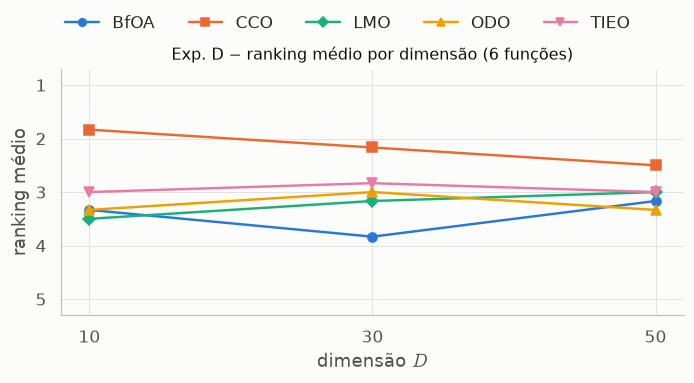

In [29]:
rk = {D: ranks(D_res[D_res.D == D]) for D in SCAL_DIMS}
frD = {D: friedman(r) for D, r in rk.items()}
frD_all = friedman(pd.concat(rk.values()))
avg = pd.DataFrame({f"D = {D}": fr["Rbar"] for D, fr in frD.items()}).T[ALG_NAMES]
avg.loc["Todas (N = 18)"] = frD_all["Rbar"]
display(avg.round(2))
for D, fr in frD.items():
    print(friedman_text(fr, f"D = {D} — "))
print(friedman_text(frD_all, "Todas as dimensões — "))

fig, ax = plt.subplots(figsize=(6.2, 3.4))
for a in ALG_NAMES:
    ax.plot(SCAL_DIMS, [frD[D]["Rbar"][a] for D in SCAL_DIMS], color=COLORS[a], marker=MARKERS[a], ms=6, label=a)
ax.set(xticks=SCAL_DIMS,
       xlabel=r"dimensão $D$",
       ylabel=r"ranking médio",
       ylim=(5.3, 0.7),
       title=r"Exp. D $-$ ranking médio por dimensão (6 funções)")
legend(fig, "upper")
fig.savefig(FIGS / "fig_exp_d_ranking.pdf", bbox_inches="tight")
plt.show()
